# Gợi ý sản phẩm theo ngân sách trên REES46: toàn bộ phần ML

**Người làm:** Dương · **Phần việc:** ML recommendation (Dataset, EDA, Processing, Feature Engineering, Training, Evaluation, Inference)

Notebook này **chứa toàn bộ code** của phần ML và đi lần lượt qua mọi bước, mỗi bước có giải thích **làm gì, vì sao, và kết quả ra sao**. Chỉ cần notebook này và dữ liệu là chạy lại được từ đầu (`Restart & Run All`).

**Bài toán.** Tại một thời điểm, dự đoán user sẽ **mua** món nào trong **7 ngày tới**, rồi gợi ý top 10 món nằm trong ngân sách của user. Đây là khối *V1 · Product recommendations* trong kiến trúc hệ thống (use case B03).

**Cách tiếp cận: hai tầng.**
1. **Sinh ứng viên:** từ hàng trăm nghìn sản phẩm, lọc thô ra khoảng 140 món mỗi user bằng 5 nguồn (lịch sử xem, món hot, cùng phiên, hot theo danh mục, ALS).
2. **Xếp hạng:** tính feature cho từng cặp (user, món ứng viên), mô hình học thứ tự (LightGBM ranker) chấm điểm, lọc theo ngân sách, lấy top N.

**Kết quả chính (lần chạy final, mẫu 5% user).**

| | NDCG@10 (tập test) |
|---|---|
| **LightGBM ranker, 47 feature (bàn giao)** | **≈ 0.269** |
| Baseline tốt nhất: gợi ý lại món vừa xem | 0.217 |
| Baseline món phổ biến | 0.117 |

Mô hình hơn baseline tốt nhất khoảng **24%**, chênh lệch có khoảng tin cậy 95% không chứa 0.

**Mục lục**

0. Cài đặt, cấu hình và tham số
1. Dữ liệu
2. Bài toán và chia dữ liệu theo thời gian
3. Tầng 1: sinh ứng viên (và chẩn đoán phần bị sót)
4. Feature engineering
5. Huấn luyện
6. Đánh giá và so sánh mô hình
7. Ablation: feature nào thật sự có ích
8. Feature importance
9. Lưu mô hình và kết quả
10. Inference: dùng mô hình để gợi ý
11. Kết luận, hạn chế và yêu cầu dữ liệu cho database

**Dữ liệu cần có:** `data/2019-Dec_5pct.parquet` và `data/2020-Jan_5pct.parquet` (mẫu 5% user của REES46). Tạo bằng `python prepare_data.py` từ dữ liệu gốc, hoặc nhận file từ Dương; xem `README.md`.

**Thời gian chạy:** khoảng 15–20 phút với mẫu 5% user (sinh ứng viên và tính feature khoảng 5 phút, ablation khoảng 5–10 phút).

## 0. Cài đặt, cấu hình và tham số

Thư viện cần: `pandas numpy pyarrow scikit-learn lightgbm xgboost implicit scipy joblib matplotlib`.

```
pip install pandas numpy pyarrow scikit-learn lightgbm xgboost implicit scipy joblib matplotlib
```

`implicit` dùng cho nguồn ứng viên ALS; nếu không cài được, notebook vẫn chạy và bỏ qua nguồn này.

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")   # đặt trước khi import numpy: ALS chạy ổn định, không cảnh báo
os.environ.setdefault("MKL_NUM_THREADS", "1")

import glob
import json
import time
import warnings
from dataclasses import dataclass, field, replace

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

_t0 = time.time()
def tick(msg):
    print(f"[{time.time() - _t0:6.0f}s] {msg}", flush=True)

**Cấu hình chung.** Mọi tham số của pipeline nằm trong một chỗ: số món lấy từ mỗi nguồn ứng viên, độ dài cửa sổ nhãn, số mẫu âm, chỉ số dùng để chọn mô hình...

In [2]:
@dataclass
class Config:
    # Dữ liệu
    data_paths: list = field(default_factory=list)   # CSV / CSV.GZ / Parquet của REES46
    out_dir: str = "artifacts"
    sample_users_frac: float = 1.0                   # Lấy mẫu theo user để vừa RAM (vd 0.2)
    min_user_events: int = 3                         # Bỏ user quá ít tương tác

    # Chia theo thời gian: 3 cửa sổ nhãn liên tiếp ở cuối dữ liệu (train | val | test)
    label_days: int = 7
    target_events: tuple = ("purchase",)             # Nhãn dương. Có thể thêm "cart"

    # Ứng viên
    hist_top: int = 50          # Món user đã tương tác gần đây
    pop_top: int = 50           # Món phổ biến toàn sàn
    covisit_top: int = 50       # Món hay xuất hiện cùng phiên với món user đã xem
    catpop_top: int = 20        # Món phổ biến trong mỗi danh mục yêu thích (top 3 danh mục)
    als_top: int = 50           # Gợi ý ALS (nếu cài implicit)
    use_als: bool = True

    # Huấn luyện và đánh giá
    neg_per_user: int = 50      # Giới hạn số mẫu âm mỗi user khi train ranker
    k_list: tuple = (5, 10, 20)
    select_metric: str = "ndcg@10"    # Chọn mô hình tốt nhất theo validation
    seed: int = 42
    exclude_groups: tuple = ()        # Nhóm feature bỏ ra khi train (vd ("dynamics",) để quay về bộ 45 feature)
    exclude_features: tuple = ()      # Feature lẻ bỏ ra khi train (vd các feature ablation cho thấy là nhiễu)
    final_model: str = ""             # Ép mô hình được lưu để bàn giao (rỗng = mô hình tốt nhất trên validation)
    n_seeds: int = 3                  # Số seed cho mỗi cấu hình ablation (giảm nhiễu khi train)
    n_boot: int = 1000                # Số lần bootstrap khi so sánh cặp

**Tham số của lần chạy này.**

- `EXCLUDE`: 5 feature đã thử ở lần thử nghiệm v3 nhưng không chứng minh được là có ích (xem mục 7), nên không đưa vào mô hình. Code tính các feature này vẫn được giữ ở mục 4 để thấy đã thử những gì.
- `RUN_ABLATION`: ablation train lại LightGBM khoảng 50 lần (mất thêm 5–10 phút). Đặt `False` để đọc kết quả đã lưu ở `ARTIFACTS/results/ablation.csv` nếu có.
- `RUN_LEAKAGE_CHECK`: kiểm tra chống rò rỉ dữ liệu ngay trên dữ liệu thật (1–2 phút).

In [3]:
DATA_PATHS = ["data/2019-Dec_5pct.parquet", "data/2020-Jan_5pct.parquet"]
ARTIFACTS = "artifacts"              # nơi lưu mô hình và kết quả (mục 9)
RUN_ABLATION = True
RUN_LEAKAGE_CHECK = True

EXCLUDE = ["ui_views_last_session", "ui_price_change", "item_price_change_30d",
           "ui_view_share_30d", "ui_cat_views_1d"]

cfg = Config(data_paths=DATA_PATHS, out_dir=ARTIFACTS, exclude_features=tuple(EXCLUDE),
             final_model="lgbm_ranker")
cfg

Config(data_paths=['data/2019-Dec_5pct.parquet', 'data/2020-Jan_5pct.parquet'], out_dir='artifacts', sample_users_frac=1.0, min_user_events=3, label_days=7, target_events=('purchase',), hist_top=50, pop_top=50, covisit_top=50, catpop_top=20, als_top=50, use_als=True, neg_per_user=50, k_list=(5, 10, 20), select_metric='ndcg@10', seed=42, exclude_groups=(), exclude_features=('ui_views_last_session', 'ui_price_change', 'item_price_change_30d', 'ui_view_share_30d', 'ui_cat_views_1d'), final_model='lgbm_ranker', n_seeds=3, n_boot=1000)

## 1. Dữ liệu

**Bộ dữ liệu:** REES46, log hành vi của một sàn thương mại điện tử đa ngành (dùng tháng 12/2019 và 1/2020). Mỗi dòng là một sự kiện: `event_time, event_type (view | cart | purchase), product_id, category_id, category_code, brand, price, user_id, user_session`.

**Vì sao chọn REES46:** có đủ ba loại hành vi xem, thêm giỏ, mua; có giá ở mọi sự kiện (cần cho bài toán ngân sách); có phiên (session) và danh mục; đủ lớn.

**Các phát hiện EDA quyết định cách làm** (chi tiết trong `01_eda_rees46.ipynb`):

| Phát hiện | Ảnh hưởng tới cách làm |
|---|---|
| 99,8% món được mua đều được xem trước, nhưng trung vị từ lúc xem đến lúc mua chỉ khoảng 3 phút; chỉ 14,7% được xem trước đó hơn 1 ngày | Lịch sử xem là tín hiệu mạnh nhất; đồng thời nhiều món chỉ được xem lần đầu sau mốc dự đoán, nên có một trần tự nhiên cho độ chính xác |
| Xem 93,8%, thêm giỏ 4,7%, mua 1,5% | Nhãn "mua" rất hiếm; thêm giỏ là tín hiệu mạnh |
| Trung vị mỗi user chỉ 3 sự kiện | Dữ liệu rất thưa: các phương pháp học sở thích ẩn (ALS) sẽ yếu |
| 1% sản phẩm chiếm 53,6% lượt tương tác | "Món phổ biến" là baseline phải thắng; cần đo thêm độ phủ (coverage) |
| `category_code` bị gán nhãn sai | Chỉ dùng `category_id` |
| 11,7% thiếu `brand` | Feature thương hiệu kém tin cậy ở phần này |
| 17% cặp (user, món) được mua lặp lại | Không loại món đã mua khỏi gợi ý; có feature số lần đã mua |

### 1.1. Đọc và làm sạch

- Đọc CSV hoặc Parquet; bỏ đuôi `" UTC"` ở thời gian.
- (Tùy chọn) lấy mẫu theo user bằng hash cố định, để lần chạy nào cũng ra cùng tập user. File 5% đã được lấy mẫu sẵn theo user trong `prepare_data.py`.
- Bỏ giá ≤ 0, bỏ dòng trùng, bỏ user có dưới 3 sự kiện; điền `brand`, `category_code` thiếu bằng `"unknown"`.
- Gán **trọng số** cho từng loại sự kiện (xem 1, thêm giỏ 3, mua 5), dùng khi tính độ phổ biến và ALS.

In [4]:
COLUMNS = ["event_time", "event_type", "product_id", "category_id", "category_code",
           "brand", "price", "user_id", "user_session"]
EVENT_TYPES = ["view", "cart", "remove_from_cart", "purchase"]
# Trọng số dùng cho điểm phổ biến / ALS / co-visitation
EVENT_WEIGHT = {"view": 1.0, "cart": 3.0, "remove_from_cart": 0.0, "purchase": 5.0}


def _read_one(path, usecols):
    if path.endswith(".parquet"):
        return pd.read_parquet(path, columns=usecols)
    return pd.read_csv(path, usecols=usecols,
                       dtype={"event_type": "category", "product_id": "int64",
                              "category_id": "int64", "category_code": "category",
                              "brand": "category", "price": "float32",
                              "user_id": "int64", "user_session": "category"})


def load_events(cfg) -> pd.DataFrame:
    paths = []
    for p in cfg.data_paths:
        paths.extend(sorted(glob.glob(p)) or [p])
    df = pd.concat([_read_one(p, COLUMNS) for p in paths], ignore_index=True)

    # Thời gian: REES46 ghi "2019-10-01 00:00:00 UTC"
    df["event_time"] = pd.to_datetime(df["event_time"].astype(str).str.replace(" UTC", "", regex=False),
                                      utc=True).dt.tz_localize(None)
    df["event_type"] = df["event_type"].astype(str)
    df = df[df["event_type"].isin(EVENT_TYPES)]

    # Lấy mẫu theo user (băm cố định để lần chạy nào cũng ra cùng tập user)
    if cfg.sample_users_frac < 1.0:
        h = (df["user_id"].to_numpy(dtype=np.uint64) * np.uint64(2654435761)) % np.uint64(10_000)
        df = df[h < np.uint64(int(cfg.sample_users_frac * 10_000))]

    # Làm sạch
    df = df[df["price"] > 0]
    df = df.drop_duplicates(subset=["event_time", "event_type", "product_id", "user_id"])
    cnt = df.groupby("user_id")["product_id"].transform("size")
    df = df[cnt >= cfg.min_user_events]

    df["category_code"] = df["category_code"].astype("string").fillna("unknown")
    df["brand"] = df["brand"].astype("string").fillna("unknown")
    df["top_category"] = df["category_code"].str.split(".").str[0]
    df["user_session"] = df["user_session"].astype("string").fillna("na")
    df["weight"] = df["event_type"].map(EVENT_WEIGHT).astype("float32")
    return df.sort_values("event_time").reset_index(drop=True)

In [5]:
df = load_events(cfg)
tick("đã đọc dữ liệu")
display(pd.Series({
    "Số sự kiện": f"{len(df):,}",
    "Số user": f"{df['user_id'].nunique():,}",
    "Số sản phẩm": f"{df['product_id'].nunique():,}",
    "Số danh mục": f"{df['category_id'].nunique():,}",
    "Từ": str(df["event_time"].min()),
    "Đến": str(df["event_time"].max()),
}, name="Giá trị").to_frame())
display((df["event_type"].value_counts(normalize=True) * 100).round(2).rename("% sự kiện").to_frame())

[    55s] đã đọc dữ liệu


,Giá trị
Số sự kiện,"5,960,998"
Số user,"221,117"
Số sản phẩm,"157,620"
Số danh mục,"1,168"
Từ,2019-12-01 00:00:17
Đến,2020-01-31 23:59:58


,% sự kiện
event_type,
view,93.5500
cart,4.7900
purchase,1.6600


## 2. Bài toán và chia dữ liệu theo thời gian

**Định nghĩa.** Chọn một mốc thời gian `t`:
- **Feature** chỉ được tính từ dữ liệu **trước** `t`.
- **Nhãn** = các món user **mua** trong 7 ngày `[t, t + 7 ngày)`.

**Vì sao chia theo thời gian, không chia ngẫu nhiên.** Khi chạy thật, hệ thống chỉ biết quá khứ. Chia ngẫu nhiên sẽ để mô hình "nhìn thấy tương lai" và cho điểm cao giả tạo.

Ba mốc liên tiếp ở cuối dữ liệu, mỗi mốc cách nhau 7 ngày:
- **train**: dùng để học;
- **val**: dùng để dừng sớm và **chọn mô hình**;
- **test**: chỉ dùng để **báo cáo**, không dùng để chọn gì cả.

Chỉ đánh giá trên user **có lịch sử trước mốc** và **có mua trong 7 ngày**. User mới hoàn toàn được hệ thống phục vụ bằng danh sách phổ biến, không qua mô hình.

In [6]:
def time_splits(df, cfg):
    """Trả về 3 mốc cắt (train, val, test). Mỗi mốc t: feature dùng dữ liệu < t,
    nhãn là sự kiện mục tiêu trong [t, t + label_days)."""
    end = df["event_time"].max().normalize() + pd.Timedelta(days=1)
    L = pd.Timedelta(days=cfg.label_days)
    return {"train": end - 3 * L, "val": end - 2 * L, "test": end - L}, L


def labels(df, t, L, cfg):
    m = (df["event_time"] >= t) & (df["event_time"] < t + L) & df["event_type"].isin(cfg.target_events)
    lab = df.loc[m, ["user_id", "product_id"]].drop_duplicates()
    lab["label"] = 1
    return lab

In [7]:
cuts, L = time_splits(df, cfg)
S = {}
rows = []
for name, t in cuts.items():
    lab = labels(df, t, L, cfg)
    users = np.intersect1d(lab["user_id"].unique(), df.loc[df["event_time"] < t, "user_id"].unique())
    truth = lab[lab["user_id"].isin(users)].groupby("user_id")["product_id"].apply(list)
    S[name] = {"t": t, "lab": lab, "users": users, "truth": truth}
    rows.append({"split": name, "mốc t": t.date(), "nhãn đến": (t + L).date(),
                 "user được đánh giá": len(users), "cặp (user, món) được mua": int(truth.str.len().sum())})
display(pd.DataFrame(rows).set_index("split"))

,mốc t,nhãn đến,user được đánh giá,"cặp (user, món) được mua"
split,,,,
train,2020-01-11,2020-01-18,3998,5957
val,2020-01-18,2020-01-25,4561,6745
test,2020-01-25,2020-02-01,4128,6267


## 3. Tầng 1: sinh ứng viên

**Vì sao cần tầng này.** Mô hình xếp hạng phải tính 47 feature cho **mỗi cặp (user, món)**. Chấm mọi món cho mọi user là hàng trăm triệu cặp, không khả thi. Tầng ứng viên lọc thô xuống khoảng 140 món mỗi user, rồi tầng xếp hạng làm việc kỹ trên phần nhỏ đó.

| | Tầng ứng viên | Tầng xếp hạng |
|---|---|---|
| Câu hỏi | Món nào **có thể** được mua? | Trong số đó, món nào **nhất**? |
| Tối ưu cho | Không bỏ sót (recall) | Đúng thứ tự (NDCG) |
| Yêu cầu | Rẻ, nhanh | Có thể tốn kém, vì chỉ chạy trên ~140 món |

**Mỗi nguồn ứng viên là một giả thuyết "vì sao người ta mua".** Món được mua mà không khớp giả thuyết nào sẽ bị sót. Mỗi nguồn trả về `(user_id, product_id, <điểm của nguồn>)`; điểm này được giữ lại làm feature cho tầng xếp hạng.

Mọi nguồn chỉ dùng dữ liệu **trước** mốc `t`.

In [8]:
def _recent(hist, t, days):
    return hist[hist["event_time"] >= t - pd.Timedelta(days=days)]

### Nguồn 1: lịch sử xem — "tôi mua cái tôi đang cân nhắc"

50 món user tương tác gần nhất trong 30 ngày, xếp theo lần tương tác cuối (`hist_rank = 1` là món mới nhất). EDA cho thấy đây là nguồn quan trọng nhất.

In [9]:
def from_history(hist, users, t, top):
    """Món user đã tương tác. Trong thương mại điện tử, người mua rất hay quay lại món đã xem/thêm giỏ."""
    h = _recent(hist[hist["user_id"].isin(users)], t, 30)
    g = h.groupby(["user_id", "product_id"]).agg(last=("event_time", "max"), w=("weight", "sum")).reset_index()
    g = g.sort_values(["user_id", "last"], ascending=[True, False])
    g["hist_rank"] = g.groupby("user_id").cumcount() + 1
    return g[g["hist_rank"] <= top][["user_id", "product_id", "hist_rank"]]

### Nguồn 2: món hot — "tôi mua cái mọi người đang mua"

50 món có tổng trọng số tương tác cao nhất toàn sàn trong 7 ngày; giống nhau cho mọi user. Cũng là danh sách fallback cho user mới.

In [10]:
def popular(hist, t, top):
    h = _recent(hist, t, 7)
    s = h.groupby("product_id")["weight"].sum().sort_values(ascending=False).head(top)
    return pd.DataFrame({"product_id": s.index, "pop_rank": np.arange(1, len(s) + 1)})


def from_popular(pop, users):
    u = pd.DataFrame({"user_id": users})
    return u.merge(pop, how="cross")

### Nguồn 3: cùng phiên (co-visitation) — "xem A thì người ta cũng xem B"

Đếm số phiên mà hai món cùng xuất hiện (30 ngày, bỏ phiên chỉ có 1 món hoặc quá 30 món). Với 10 món user xem gần nhất, lấy các món hay đi cùng chúng nhất. Bắt được món thay thế và món đi kèm.

In [11]:
def covisitation(hist, users, t, top, max_session_items=30):
    """Hai món xuất hiện trong cùng một phiên thì có liên quan (giống "người xem món này cũng xem...")."""
    h = _recent(hist, t, 30)[["user_session", "product_id"]].drop_duplicates()
    h = h[h.groupby("user_session")["product_id"].transform("size").between(2, max_session_items)]
    pairs = h.merge(h, on="user_session", suffixes=("", "_b"))
    pairs = pairs[pairs["product_id"] != pairs["product_id_b"]]
    co = pairs.groupby(["product_id", "product_id_b"]).size().rename("co").reset_index()
    co = co.sort_values(["product_id", "co"], ascending=[True, False])
    co = co[co.groupby("product_id").cumcount() < 20]

    seeds = _recent(hist[hist["user_id"].isin(users)], t, 30)
    seeds = seeds.sort_values("event_time").groupby("user_id").tail(10)[["user_id", "product_id"]].drop_duplicates()
    c = seeds.merge(co, on="product_id")
    c = c.groupby(["user_id", "product_id_b"])["co"].sum().rename("covisit_score").reset_index()
    c = c.rename(columns={"product_id_b": "product_id"})
    c = c.sort_values(["user_id", "covisit_score"], ascending=[True, False])
    return c[c.groupby("user_id").cumcount() < top]

### Nguồn 4: hot theo danh mục — "món nổi trong loại tôi thích"

3 danh mục user tương tác nhiều nhất; trong mỗi danh mục lấy 20 món phổ biến nhất 7 ngày.

In [12]:
def category_popular(hist, users, t, top):
    """Món phổ biến trong 3 danh mục user quan tâm nhất."""
    h = _recent(hist, t, 30)
    ucat = h[h["user_id"].isin(users)].groupby(["user_id", "category_id"])["weight"].sum().reset_index()
    ucat = ucat.sort_values(["user_id", "weight"], ascending=[True, False])
    ucat = ucat[ucat.groupby("user_id").cumcount() < 3][["user_id", "category_id"]]
    pc = _recent(hist, t, 7).groupby(["category_id", "product_id"])["weight"].sum().reset_index()
    pc = pc.sort_values(["category_id", "weight"], ascending=[True, False])
    pc["catpop_rank"] = pc.groupby("category_id").cumcount() + 1
    pc = pc[pc["catpop_rank"] <= top]
    out = ucat.merge(pc[["category_id", "product_id", "catpop_rank"]], on="category_id")
    return out.groupby(["user_id", "product_id"])["catpop_rank"].min().reset_index()

### Nguồn 5: ALS — "người giống tôi mua gì"

Collaborative filtering cho dữ liệu ngầm (thư viện `implicit`): phân rã ma trận user × món (trọng số tương tác 60 ngày, lấy log) thành vector sở thích ẩn, rồi gợi ý món gần với vector của user. Dữ liệu càng thưa thì nguồn này càng yếu.

In [13]:
def als(hist, users, t, top, factors=64, iterations=15, seed=42):
    """Collaborative filtering (ALS cho dữ liệu ngầm). Trả về None nếu chưa cài thư viện implicit."""
    try:
        from implicit.als import AlternatingLeastSquares
        from scipy.sparse import csr_matrix
    except ImportError:
        return None
    h = _recent(hist, t, 60)
    g = h.groupby(["user_id", "product_id"])["weight"].sum().reset_index()
    g = g[g["weight"] > 0]
    uidx = {u: i for i, u in enumerate(g["user_id"].unique())}
    iids = g["product_id"].unique()
    iidx = {p: i for i, p in enumerate(iids)}
    rows = g["user_id"].map(uidx).to_numpy()
    cols = g["product_id"].map(iidx).to_numpy()
    mat = csr_matrix((np.log1p(g["weight"].to_numpy(dtype=np.float32)), (rows, cols)),
                     shape=(len(uidx), len(iidx)))
    model = AlternatingLeastSquares(factors=factors, iterations=iterations, random_state=seed)
    model.fit(mat, show_progress=False)
    target = [u for u in users if u in uidx]
    if not target:
        return None
    ui = np.array([uidx[u] for u in target])
    ids, scores = model.recommend(ui, mat[ui], N=top, filter_already_liked_items=False)
    out = pd.DataFrame({"user_id": np.repeat(target, ids.shape[1]),
                        "product_id": iids[ids.ravel()],
                        "als_score": scores.ravel().astype("float32")})
    return out

### Gộp các nguồn

Gộp ngoài (outer join) theo cặp (user, món): món trùng giữa các nguồn chỉ giữ một dòng, với điểm của từng nguồn ở các cột riêng.

**Candidate recall** = tỷ lệ món user thật sự mua có nằm trong danh sách ứng viên (trung bình theo user). Đây là **trần** của cả hệ thống: món không có trong danh sách thì không bao giờ được gợi ý.

In [14]:
def generate(hist, users, t, cfg):
    hist = hist[hist["event_time"] < t]          # chốt chặn rò rỉ
    users = np.asarray(users)
    parts = [from_history(hist, users, t, cfg.hist_top),
             from_popular(popular(hist, t, cfg.pop_top), users),
             covisitation(hist, users, t, cfg.covisit_top),
             category_popular(hist, users, t, cfg.catpop_top)]
    if cfg.use_als:
        a = als(hist, users, t, cfg.als_top, seed=cfg.seed)
        if a is not None:
            parts.append(a)
    cand = parts[0]
    for p in parts[1:]:
        cand = cand.merge(p, on=["user_id", "product_id"], how="outer")
    return cand.reset_index(drop=True)


def candidate_recall(cand, truth):
    """Giới hạn trên: tỷ lệ món mua thật có nằm trong tập ứng viên."""
    c = cand.groupby("user_id")["product_id"].apply(set)
    vals = [len(set(rel) & c.get(u, set())) / len(rel) for u, rel in truth.items()]
    return float(np.mean(vals))

In [15]:
for name in ("train", "val", "test"):
    s = S[name]
    hist = df[df["event_time"] < s["t"]]
    s["cand"] = generate(hist, s["users"], s["t"], cfg)
    s["n_catalog"] = hist["product_id"].nunique()
    tick(f"{name}: {len(s['cand']):,} cặp ứng viên")
del hist

display(pd.DataFrame([{
    "split": n,
    "cặp ứng viên": len(S[n]["cand"]),
    "món / user": len(S[n]["cand"]) / len(S[n]["users"]),
    "candidate recall": candidate_recall(S[n]["cand"], S[n]["truth"]),
} for n in ("train", "val", "test")]).set_index("split"))

[   132s] train: 582,124 cặp ứng viên
[   171s] val: 658,849 cặp ứng viên
[   203s] test: 590,626 cặp ứng viên


,cặp ứng viên,món / user,candidate recall
split,,,
train,582124,145.6038,0.6125
val,658849,144.4528,0.6104
test,590626,143.0780,0.6070


### 3.1. Mỗi nguồn đóng góp bao nhiêu (tập test)

- **Recall một mình**: nếu chỉ dùng nguồn này thì bắt được bao nhiêu % món được mua.
- **Chỉ nguồn này bắt được**: % món được mua mà **không nguồn nào khác** bắt được. Đây là giá trị thật của một nguồn: nguồn có recall cao nhưng toàn trùng với nguồn khác thì bỏ đi cũng không mất gì.

In [16]:
SRC = {"Lịch sử xem": "hist_rank", "Món hot": "pop_rank", "Cùng phiên": "covisit_score",
       "Hot theo loại": "catpop_rank", "ALS": "als_score"}
c = S["test"]["cand"]
flags = c[["user_id", "product_id"]].copy()
for k, col in SRC.items():
    flags[k] = c[col].notna() if col in c.columns else False
tp = S["test"]["truth"].explode().rename("product_id").reset_index()
m = tp.merge(flags, on=["user_id", "product_id"], how="left")
m[list(SRC)] = m[list(SRC)].fillna(False).astype(bool)

def user_recall(found):                       # trung bình theo user, giống candidate_recall
    return found.groupby(m["user_id"]).mean().mean()

rows = []
for k in SRC:
    others = m[[x for x in SRC if x != k]].any(axis=1)
    rows.append({"nguồn": k,
                 "món / user": flags[k].sum() / flags["user_id"].nunique(),
                 "recall một mình": user_recall(m[k]),
                 "chỉ nguồn này bắt được": user_recall(m[k] & ~others)})
rows.append({"nguồn": "Tất cả (hợp lại)", "món / user": len(c) / c["user_id"].nunique(),
             "recall một mình": user_recall(m[list(SRC)].any(axis=1)), "chỉ nguồn này bắt được": np.nan})
display(pd.DataFrame(rows).set_index("nguồn"))

,món / user,recall một mình,chỉ nguồn này bắt được
nguồn,,,
Lịch sử xem,14.4179,0.2893,0.0344
Món hot,50.0000,0.3446,0.0802
Cùng phiên,38.0686,0.3141,0.0179
Hot theo loại,43.1524,0.3083,0.0090
ALS,50.0000,0.3058,0.0304
Tất cả (hợp lại),143.0780,0.6070,NaN


### 3.2. Phần bị sót là những món nào

Chia các món được mua nhưng **không nguồn nào bắt được** theo lý do. Mỗi nhóm ứng với một cách sửa khác nhau:

| Nhóm | Ý nghĩa | Cách sửa |
|---|---|---|
| Xem lần đầu sau mốc, **danh mục user đã từng xem** | User khám phá món mới trong loại quen | Nguồn mới "món cùng danh mục, trong ngân sách" có thể bắt được |
| Xem lần đầu sau mốc, **danh mục mới** | User chuyển sang nhu cầu khác hẳn | Gần như không đoán được |
| Đã tương tác trước mốc nhưng bị loại | Quá 30 ngày, hoặc ngoài top 50 lịch sử | Lấy sâu hoặc xa hơn trong lịch sử |
| Mua mà không có lượt xem nào ghi nhận | Mua trực tiếp, log thiếu | Không sửa được ở tầng này |

In [17]:
t = S["test"]["t"]
hist_t = df[df["event_time"] < t]
win = df[(df["event_time"] >= t) & (df["event_time"] < t + L)]
miss = m.loc[~m[list(SRC)].any(axis=1), ["user_id", "product_id"]]

seen = hist_t[["user_id", "product_id"]].drop_duplicates().assign(seen_before=True)
viewed = win.loc[win["event_type"] == "view", ["user_id", "product_id"]].drop_duplicates().assign(viewed_in_window=True)
pcat = df.drop_duplicates("product_id")[["product_id", "category_id"]]
ucat = hist_t[["user_id", "category_id"]].drop_duplicates().assign(cat_seen=True)

d = (miss.merge(seen, how="left").merge(viewed, how="left")
         .merge(pcat, how="left").merge(ucat, how="left"))
for col in ("seen_before", "viewed_in_window", "cat_seen"):
    d[col] = d[col].fillna(False).astype(bool)
d["nhóm"] = np.select(
    [d["seen_before"],
     d["viewed_in_window"] & d["cat_seen"],
     d["viewed_in_window"] & ~d["cat_seen"]],
    ["Đã tương tác trước mốc nhưng bị loại",
     "Xem lần đầu sau mốc, danh mục user đã từng xem",
     "Xem lần đầu sau mốc, danh mục mới"],
    "Mua mà không có lượt xem nào ghi nhận")
miss_tab = d["nhóm"].value_counts().rename("số cặp").to_frame()
miss_tab["% phần bị sót"] = miss_tab["số cặp"] / len(d) * 100
miss_tab["% tổng số món được mua"] = miss_tab["số cặp"] / len(m) * 100
display(miss_tab)
del hist_t, win, seen, viewed, ucat

,số cặp,% phần bị sót,% tổng số món được mua
nhóm,,,
"Xem lần đầu sau mốc, danh mục mới",1598,62.8639,25.4986
"Xem lần đầu sau mốc, danh mục user đã từng xem",814,32.0220,12.9887
Đã tương tác trước mốc nhưng bị loại,78,3.0685,1.2446
Mua mà không có lượt xem nào ghi nhận,52,2.0456,0.8297


**Cách đọc.** Cột cuối cộng lại bằng phần bị sót (khoảng 39% ở lần chạy final). Nhóm *"danh mục user đã từng xem"* là phần mà một nguồn ứng viên mới theo danh mục và ngân sách có thể lấy lại, tức là **mức tăng trần tối đa** của hướng cải thiện đó. Nhóm *"danh mục mới"* gần như là giới hạn tự nhiên của bài toán.

## 4. Feature engineering

**Nguyên tắc.**

1. **Chỉ dùng quá khứ.** Mọi feature tính từ dữ liệu trước mốc `t`. `build_features` có chốt chặn ở dòng đầu tiên, và có kiểm tra tự động (mục 4.10).
2. **Mỗi feature phải có lý do.** Feature được khai báo trong một danh mục (`FEATURES`) kèm nhóm, cách tính và **vì sao giúp ích**. Bảng danh mục và file `feature_catalog.md` đều sinh tự động từ đây.
3. **Không dùng ID.** Feature là số đếm, thứ hạng, tỷ lệ, nên mô hình không học thuộc từng sản phẩm, và logic dùng được cho dữ liệu khác.
4. **Train và inference dùng chung một hàm** (`build_features`), nên không lệch giữa lúc học và lúc chạy thật.

**7 nhóm feature:**

| Nhóm | Câu hỏi | Ví dụ |
|---|---|---|
| candidate | Món được nguồn ứng viên nào chỉ tới, thứ mấy? | `hist_rank`, `pop_rank`, `n_sources` |
| item | Món này đang bán chạy, được quan tâm không? | `item_purchases_30d`, `item_cart_rate` |
| user | User này hoạt động thế nào? | `user_days_since_last` |
| user_item | User đã làm gì với **chính món này**? | `ui_views`, `ui_days_since_last`, `ui_carts` |
| affinity | User có hợp thương hiệu, danh mục của món không? | `aff_brand`, `aff_category` |
| price_budget | Giá món so với mức giá quen thuộc và ngân sách | `price_z_user`, `budget_ratio` |
| dynamics (thử ở v3) | Thông tin mới: giảm giá, độ mới của giỏ, vị trí giá trong danh mục | `ui_days_since_cart`, `price_vs_user_cat` |

### 4.1. Danh mục feature

In [18]:
FEATURES = {}   # tên -> {"group", "desc", "why"}
GROUPS = ["candidate", "item", "user", "user_item", "affinity", "price_budget", "dynamics"]


def feature(name, group, desc, why):
    FEATURES[name] = {"group": group, "desc": desc, "why": why}


def feature_names(groups=None):
    gs = set(groups or GROUPS)
    return [n for n, m in FEATURES.items() if m["group"] in gs]


def describe_markdown():
    rows = ["| Nhóm | Feature | Cách tính | Vì sao giúp ích |", "| --- | --- | --- | --- |"]
    for n, m in FEATURES.items():
        rows.append(f"| {m['group']} | `{n}` | {m['desc']} | {m['why']} |")
    return "\n".join(rows)

In [19]:
# Nguồn ứng viên
feature("hist_rank", "candidate", "Thứ hạng gần đây của món trong lịch sử 30 ngày của user (1 = mới nhất)",
        "Người mua rất hay quay lại món vừa xem; món càng gần đây càng dễ được mua")
feature("pop_rank", "candidate", "Thứ hạng phổ biến toàn sàn 7 ngày gần nhất",
        "Món đang hot có xác suất mua nền cao với mọi người")
feature("covisit_score", "candidate", "Tổng số phiên mà món này xuất hiện cùng các món user vừa xem",
        "Bắt quan hệ thay thế/bổ sung giữa sản phẩm (xem điện thoại thì hay xem ốp lưng)")
feature("catpop_rank", "candidate", "Thứ hạng phổ biến trong danh mục user quan tâm",
        "Kết hợp sở thích danh mục của user với độ phổ biến trong danh mục đó")
feature("als_score", "candidate", "Điểm collaborative filtering (ALS)",
        "Học sở thích ẩn từ hành vi của những người giống nhau, tìm được món user chưa từng xem")
feature("n_sources", "candidate", "Số nguồn ứng viên cùng đề xuất món này",
        "Món được nhiều tín hiệu độc lập cùng chỉ ra thường liên quan hơn")
# Sản phẩm
for d in (1, 7, 30):
    feature(f"item_views_{d}d", "item", f"Số lượt xem trong {d} ngày", "Mức độ quan tâm hiện tại của thị trường")
    feature(f"item_carts_{d}d", "item", f"Số lượt thêm giỏ trong {d} ngày", "Ý định mua mạnh hơn lượt xem")
    feature(f"item_purchases_{d}d", "item", f"Số lượt mua trong {d} ngày", "Bằng chứng trực tiếp món bán được")
feature("item_unique_users_7d", "item", "Số user khác nhau tương tác trong 7 ngày",
        "Phân biệt món được nhiều người quan tâm với món bị một vài người xem đi xem lại")
feature("item_conv_rate", "item", "(mua + 1) / (xem + 20) trong 30 ngày (làm mượt Bayes)",
        "Tách món 'nhiều người xem' khỏi món 'nhiều người thật sự mua'; làm mượt để món ít dữ liệu không bị điểm ảo")
feature("item_cart_rate", "item", "(thêm giỏ + 1) / (xem + 20) trong 30 ngày", "Tỷ lệ biến lượt xem thành ý định mua")
feature("item_trend", "item", "Lượt xem 7 ngày quy đổi so với trung bình 30 ngày",
        "Bắt món đang tăng nhiệt, không chỉ món bán chạy lâu năm")
feature("item_age_days", "item", "Số ngày từ lần đầu món xuất hiện", "Món mới và món lâu năm có hành vi khác nhau")
feature("item_price", "item", "Giá gần nhất trước mốc cắt", "Giá ảnh hưởng trực tiếp quyết định mua")
feature("item_price_pct_in_cat", "item", "Vị trí giá trong danh mục (0 = rẻ nhất, 1 = đắt nhất)",
        "Cùng một mức giá có thể là rẻ ở danh mục này nhưng đắt ở danh mục khác")
# Người dùng
feature("user_events_30d", "user", "Số sự kiện 30 ngày", "Mức độ hoạt động của user")
feature("user_purchases_total", "user", "Tổng số lần mua trước mốc cắt", "Người đã từng mua có xác suất mua lại cao hơn hẳn")
feature("user_carts_30d", "user", "Số lần thêm giỏ 30 ngày", "User đang trong trạng thái chuẩn bị mua")
feature("user_sessions_30d", "user", "Số phiên 30 ngày", "Tần suất ghé sàn")
feature("user_days_since_last", "user", "Số ngày từ sự kiện cuối", "User vừa hoạt động dễ quay lại hơn user đã rời đi")
feature("user_unique_items_30d", "user", "Số món khác nhau đã tương tác 30 ngày", "Người xem rộng hay xem tập trung vài món")
feature("user_price_mean", "user", "Giá trung bình các món đã xem", "Mức chi tiêu quen thuộc của user")
feature("user_price_std", "user", "Độ lệch chuẩn giá các món đã xem", "User nhạy giá (xem trong khoảng hẹp) hay không")
# User x item
feature("ui_views", "user_item", "Số lần user xem món này", "Xem đi xem lại là tín hiệu mua rất mạnh")
feature("ui_views_7d", "user_item", "Số lần xem món này trong 7 ngày", "Ý định gần đây quan trọng hơn ý định cũ")
feature("ui_carts", "user_item", "Số lần user thêm món này vào giỏ", "Đã thêm giỏ là gần như quyết định")
feature("ui_removed", "user_item", "Số lần user bỏ món này khỏi giỏ", "Tín hiệu âm: đã cân nhắc rồi bỏ")
feature("ui_purchases", "user_item", "Số lần user đã mua món này", "Hàng tiêu hao (mỹ phẩm, thực phẩm) thường được mua lại")
feature("ui_days_since_last", "user_item", "Số ngày từ lần cuối user tương tác món này",
        "Tương tác càng gần mốc dự đoán càng có giá trị")
feature("ui_cart_not_bought", "user_item", "1 nếu đã thêm giỏ mà chưa mua", "Giỏ hàng bỏ dở: ý định mua còn dang dở")
feature("ui_sessions", "user_item", "Số phiên khác nhau user xem món này", "Quay lại ở nhiều phiên khác nhau là cân nhắc nghiêm túc")
# Ái lực
feature("aff_category", "affinity", "Tỷ trọng tương tác của user vào danh mục (lá) của món",
        "User hay xem danh mục nào thì dễ mua món trong danh mục đó")
feature("aff_top_category", "affinity", "Tỷ trọng tương tác của user vào danh mục cấp 1 của món",
        "Sở thích ở mức rộng hơn, hữu ích khi user chưa xem đúng danh mục lá")
feature("aff_brand", "affinity", "Tỷ trọng tương tác của user vào thương hiệu của món", "Trung thành thương hiệu")
# Giá và ngân sách
feature("price_ratio_user", "price_budget", "Giá món / giá trung bình user hay xem",
        "Món đắt hơn nhiều so với thói quen thì khó được mua")
feature("price_z_user", "price_budget", "(giá món - giá TB của user) / độ lệch chuẩn", "Món nằm trong vùng giá quen thuộc hay không")
feature("budget_ratio", "price_budget", "Giá món / ngân sách của user",
        "Gắn với yêu cầu ngân sách của đề tài: xếp ưu tiên món vừa túi, không chỉ lọc cứng")
feature("in_budget", "price_budget", "1 nếu giá <= ngân sách", "Ràng buộc cứng của đề tài (Q04); dùng để lọc sau xếp hạng")
# Động lực ngắn hạn (nhóm thử nghiệm, v3): thông tin MỚI mà các nhóm trên chưa có
feature("ui_views_last_session", "dynamics", "Số lần user xem món này trong phiên cuối cùng trước mốc",
        "Phiên cuối là ý định mới nhất; EDA cho thấy user thường mua ngay món vừa xem")
feature("ui_price_change", "dynamics", "Giá hiện tại / giá lúc user tương tác món lần cuối - 1 (âm = đã giảm)",
        "Món user đã cân nhắc mà sau đó giảm giá thì dễ được mua")
feature("item_price_change_30d", "dynamics", "Giá hiện tại / giá trung vị 30 ngày của món - 1",
        "Món đang khuyến mãi so với giá thường ngày của chính nó")
feature("ui_days_since_cart", "dynamics", "Số ngày từ lần cuối user thêm món này vào giỏ (trống nếu chưa)",
        "Giỏ hàng vừa thêm hôm qua khác hẳn giỏ hàng bỏ quên 3 tuần")
feature("ui_view_share_30d", "dynamics", "Lượt xem món này / tổng lượt xem của user trong 30 ngày",
        "Cùng 5 lượt xem: với người xem 10 món là rất tập trung, với người xem 500 món thì không")
feature("ui_cat_views_1d", "dynamics", "Số lần user xem danh mục của món trong 1 ngày gần nhất",
        "Ý định theo danh mục rất ngắn hạn; giúp món cùng loại user chưa xem (món thay thế)")
feature("price_vs_user_cat", "dynamics", "Giá món / giá trung vị các món user xem trong cùng danh mục (30 ngày)",
        "Món rẻ hơn những gì user đang cân nhắc trong cùng loại: tín hiệu cho gợi ý theo ngân sách")

In [20]:
FEATS = [f for f in feature_names() if f not in cfg.exclude_features]
catalog = pd.DataFrame([{"feature": k, "nhóm": v["group"], "cách tính": v["desc"], "vì sao giúp ích": v["why"],
                         "dùng trong mô hình": k in FEATS} for k, v in FEATURES.items()])
display(catalog.groupby("nhóm", sort=False)["dùng trong mô hình"].agg(["size", "sum"])
               .rename(columns={"size": "đã thử", "sum": "đang dùng"}).loc[GROUPS])
print(f"{len(FEATURES)} feature đã thử, {len(FEATS)} feature dùng trong mô hình")
with pd.option_context("display.max_colwidth", 120, "display.max_rows", 100):
    display(catalog)

,đã thử,đang dùng
nhóm,,
candidate,6,6
item,16,16
user,8,8
user_item,8,8
affinity,3,3
price_budget,4,4
dynamics,7,2


52 feature đã thử, 47 feature dùng trong mô hình


,feature,nhóm,cách tính,vì sao giúp ích,dùng trong mô hình
0,hist_rank,candidate,Thứ hạng gần đây của món trong lịch sử 30 ngày của user (1 = mới nhất),Người mua rất hay quay lại món vừa xem; món càng gần đây càng dễ được mua,True
1,pop_rank,candidate,Thứ hạng phổ biến toàn sàn 7 ngày gần nhất,Món đang hot có xác suất mua nền cao với mọi người,True
2,covisit_score,candidate,Tổng số phiên mà món này xuất hiện cùng các món user vừa xem,Bắt quan hệ thay thế/bổ sung giữa sản phẩm (xem điện thoại thì hay xem ốp lưng),True
3,catpop_rank,candidate,Thứ hạng phổ biến trong danh mục user quan tâm,Kết hợp sở thích danh mục của user với độ phổ biến trong danh mục đó,True
4,als_score,candidate,Điểm collaborative filtering (ALS),"Học sở thích ẩn từ hành vi của những người giống nhau, tìm được món user chưa từng xem",True
5,n_sources,candidate,Số nguồn ứng viên cùng đề xuất món này,Món được nhiều tín hiệu độc lập cùng chỉ ra thường liên quan hơn,True
6,item_views_1d,item,Số lượt xem trong 1 ngày,Mức độ quan tâm hiện tại của thị trường,True
7,item_carts_1d,item,Số lượt thêm giỏ trong 1 ngày,Ý định mua mạnh hơn lượt xem,True
8,item_purchases_1d,item,Số lượt mua trong 1 ngày,Bằng chứng trực tiếp món bán được,True
9,item_views_7d,item,Số lượt xem trong 7 ngày,Mức độ quan tâm hiện tại của thị trường,True


### 4.2. Hàm phụ và ảnh chụp sản phẩm tại mốc

`product_snapshot`: thông tin mỗi sản phẩm tại mốc `t`. Giá trong REES46 thay đổi theo thời gian, nên lấy **giá lần cuối thấy trước mốc**; `first_seen` là lần đầu sản phẩm xuất hiện (thay cho ngày đăng bán).

In [21]:
def _days(t, s):
    return (t - s).dt.total_seconds() / 86400.0


def _win(hist, t, days):
    return hist[hist["event_time"] >= t - pd.Timedelta(days=days)]


def product_snapshot(hist: pd.DataFrame) -> pd.DataFrame:
    """Thông tin sản phẩm tại thời điểm cắt: giá lấy lần cuối thấy (giá trong REES46 thay đổi theo thời gian)."""
    last = hist.sort_values("event_time").groupby("product_id").tail(1)
    snap = last[["product_id", "category_id", "category_code", "top_category", "brand", "price"]].copy()
    first = hist.groupby("product_id")["event_time"].min().rename("first_seen")
    return snap.merge(first, on="product_id").reset_index(drop=True)

### 4.3. Nhóm item: món này đang được quan tâm thế nào

Số lượt xem, thêm giỏ, mua của món trong 1, 7, 30 ngày; số người xem khác nhau; tỷ lệ chuyển đổi; xu hướng (1 ngày so với trung bình 7 ngày); giá và vị trí giá trong danh mục; tuổi của món. Đây là tín hiệu **chung cho mọi user**.

In [22]:
def item_features(hist, t, prods):
    out = prods[["product_id", "category_id", "price", "first_seen"]].copy()
    for d in (1, 7, 30):
        w = _win(hist, t, d)
        c = w.pivot_table(index="product_id", columns="event_type", values="user_id",
                          aggfunc="size", fill_value=0)
        for et, name in (("view", "views"), ("cart", "carts"), ("purchase", "purchases")):
            s = c[et] if et in c.columns else pd.Series(dtype="float64")
            out[f"item_{name}_{d}d"] = out["product_id"].map(s).fillna(0)
    u7 = _win(hist, t, 7).groupby("product_id")["user_id"].nunique()
    out["item_unique_users_7d"] = out["product_id"].map(u7).fillna(0)
    out["item_conv_rate"] = (out["item_purchases_30d"] + 1) / (out["item_views_30d"] + 20)
    out["item_cart_rate"] = (out["item_carts_30d"] + 1) / (out["item_views_30d"] + 20)
    out["item_trend"] = (out["item_views_7d"] * 30 / 7 + 1) / (out["item_views_30d"] + 1)
    out["item_age_days"] = _days(t, out["first_seen"])
    out["item_price"] = out["price"]
    out["item_price_pct_in_cat"] = out.groupby("category_id")["price"].rank(pct=True)
    return out.drop(columns=["category_id", "price", "first_seen"])

### 4.4. Nhóm user: user này hoạt động thế nào

Mức hoạt động, tỷ lệ mua, số ngày từ lần hoạt động cuối, mức giá user hay xem (trung bình, độ lệch chuẩn). Giúp mô hình phân biệt user sắp mua với user chỉ lướt xem.

In [23]:
def user_features(hist, t, users):
    h = hist[hist["user_id"].isin(users)]
    h30 = _win(h, t, 30)
    g = pd.DataFrame(index=pd.Index(users, name="user_id"))
    g["user_events_30d"] = h30.groupby("user_id").size()
    g["user_purchases_total"] = h[h["event_type"] == "purchase"].groupby("user_id").size()
    g["user_carts_30d"] = h30[h30["event_type"] == "cart"].groupby("user_id").size()
    g["user_sessions_30d"] = h30.groupby("user_id")["user_session"].nunique()
    g["user_days_since_last"] = _days(t, h.groupby("user_id")["event_time"].max())
    g["user_unique_items_30d"] = h30.groupby("user_id")["product_id"].nunique()
    v = h[h["event_type"] == "view"]
    g["user_price_mean"] = v.groupby("user_id")["price"].mean()
    g["user_price_std"] = v.groupby("user_id")["price"].std()
    fill = {c: 0 for c in g.columns if c not in ("user_days_since_last", "user_price_mean", "user_price_std")}
    return g.fillna(fill).reset_index()

### 4.5. Nhóm user_item: user đã làm gì với chính món này

Nhóm **quan trọng nhất** (mục 7): số lần xem, thêm giỏ, bỏ giỏ, mua; số lần xem trong 7 ngày; số ngày từ lần tương tác cuối; đã thêm giỏ mà chưa mua.

In [24]:
def user_item_features(hist, t, cand):
    keys = cand[["user_id", "product_id"]].drop_duplicates()
    h = hist.merge(keys, on=["user_id", "product_id"])          # chỉ các cặp ứng viên
    c = h.pivot_table(index=["user_id", "product_id"], columns="event_type", values="event_time",
                      aggfunc="size", fill_value=0)
    out = keys.set_index(["user_id", "product_id"])
    for et, name in (("view", "ui_views"), ("cart", "ui_carts"),
                     ("remove_from_cart", "ui_removed"), ("purchase", "ui_purchases")):
        out[name] = c[et] if et in c.columns else 0
    h7 = _win(h, t, 7)
    out["ui_views_7d"] = h7[h7["event_type"] == "view"].groupby(["user_id", "product_id"]).size()
    out["ui_days_since_last"] = _days(t, h.groupby(["user_id", "product_id"])["event_time"].max())
    out["ui_sessions"] = h.groupby(["user_id", "product_id"])["user_session"].nunique()
    out = out.fillna({"ui_views": 0, "ui_carts": 0, "ui_removed": 0, "ui_purchases": 0,
                      "ui_views_7d": 0, "ui_sessions": 0})
    out["ui_cart_not_bought"] = ((out["ui_carts"] > 0) & (out["ui_purchases"] == 0)).astype("int8")
    return out.reset_index()

### 4.6. Nhóm affinity: user có hợp với món không

Tỷ lệ tương tác của user dành cho thương hiệu, danh mục, danh mục cha của món. Dùng `category_id` thay vì tên danh mục vì EDA cho thấy tên bị gán nhãn sai.

In [25]:
def affinity_features(hist, t, cand, prods):
    h = _win(hist[hist["user_id"].isin(cand["user_id"].unique())], t, 30)
    tot = h.groupby("user_id")["weight"].sum().rename("tot")
    c = cand[["user_id", "product_id"]].merge(prods[["product_id", "category_id", "top_category", "brand"]],
                                              on="product_id", how="left")
    for col, name in (("category_id", "aff_category"), ("top_category", "aff_top_category"), ("brand", "aff_brand")):
        s = h.groupby(["user_id", col])["weight"].sum().rename(name).reset_index()
        c = c.merge(s, on=["user_id", col], how="left")
    c = c.merge(tot, on="user_id", how="left")
    for name in ("aff_category", "aff_top_category", "aff_brand"):
        c[name] = (c[name] / c["tot"]).fillna(0)
    # brand "unknown" không mang thông tin
    c.loc[c["brand"] == "unknown", "aff_brand"] = 0
    return c[["user_id", "product_id", "aff_category", "aff_top_category", "aff_brand"]]

### 4.7. Nhóm dynamics (thử nghiệm v3)

7 feature mang **thông tin mới** mà các nhóm trên chưa có: giảm giá, độ mới của giỏ hàng, mức tập trung của user vào món, ý định theo danh mục trong 24 giờ, vị trí giá so với các món user đang xem cùng loại. Kết quả: chỉ `price_vs_user_cat` và `ui_days_since_cart` được giữ (mục 7).

In [26]:
def dynamics_features(hist, t, cand, prods):
    """Nhóm thử nghiệm: thay đổi giá, độ mới của giỏ hàng, mức tập trung, ý định danh mục ngắn hạn."""
    keys = cand[["user_id", "product_id"]].drop_duplicates()
    hu = hist[hist["user_id"].isin(keys["user_id"].unique())].sort_values("event_time")
    h = hu.merge(keys, on=["user_id", "product_id"])              # giữ thứ tự thời gian của hu
    pair = ["user_id", "product_id"]
    out = keys.set_index(pair)

    # 1. phiên cuối
    last_sess = hu.groupby("user_id")["user_session"].last()
    hl = h[h["user_session"].values == h["user_id"].map(last_sess).values]
    out["ui_views_last_session"] = hl[hl["event_type"] == "view"].groupby(pair).size()

    # 2-3. thay đổi giá (giá hiện tại = giá lần cuối thấy trên sàn)
    cur = prods.set_index("product_id")["price"]
    seen_px = h.groupby(pair)["price"].last()
    out["ui_price_change"] = seen_px.index.get_level_values("product_id").map(cur).to_numpy() / seen_px - 1
    cp = keys["product_id"].unique()
    w30 = _win(hist[hist["product_id"].isin(cp)], t, 30)
    med = w30.groupby("product_id")["price"].median()
    item_chg = (cur.reindex(med.index) / med - 1).rename("item_price_change_30d")

    # 4. độ mới của giỏ hàng
    out["ui_days_since_cart"] = _days(t, h[h["event_type"] == "cart"].groupby(pair)["event_time"].max())

    # 5. mức tập trung của user vào món
    v30 = _win(hu, t, 30)
    v30 = v30[v30["event_type"] == "view"]
    tot = v30.groupby("user_id").size()
    pv = v30.merge(keys, on=pair).groupby(pair).size()
    out["ui_view_share_30d"] = pv / pv.index.get_level_values("user_id").map(tot).to_numpy()

    out = out.fillna({"ui_views_last_session": 0, "ui_view_share_30d": 0}).reset_index()

    # 6-7. ý định danh mục ngắn hạn và vị trí giá trong danh mục user đang xem
    out = out.merge(prods[["product_id", "category_id", "price"]], on="product_id", how="left")
    v1 = _win(hu, t, 1)
    c1 = v1[v1["event_type"] == "view"].groupby(["user_id", "category_id"]).size().rename("ui_cat_views_1d")
    out = out.merge(c1.reset_index(), on=["user_id", "category_id"], how="left")
    cm = v30.groupby(["user_id", "category_id"])["price"].median().rename("ucat_med").reset_index()
    out = out.merge(cm, on=["user_id", "category_id"], how="left")
    out["price_vs_user_cat"] = out["price"] / out["ucat_med"]
    out["ui_cat_views_1d"] = out["ui_cat_views_1d"].fillna(0)
    out = out.merge(item_chg.reset_index(), on="product_id", how="left")
    cols = [n for n, m in FEATURES.items() if m["group"] == "dynamics"]
    return out[pair + cols]

### 4.8. Ngân sách

REES46 không có ngân sách, nên khi đánh giá offline dùng **ngân sách mô phỏng** = phân vị 90% giá các món user đã xem. Khi chạy thật, ngân sách lấy từ tham số `max_price` của request.

In [27]:
def user_budget(hist, users):
    """Ngân sách mô phỏng cho dữ liệu offline: phân vị 90% giá các món user đã xem.
    Khi chạy thật, ngân sách lấy từ tham số max_price của request."""
    v = hist[(hist["user_id"].isin(users)) & (hist["event_type"] == "view")]
    return v.groupby("user_id")["price"].quantile(0.9).rename("budget")

### 4.9. Ghép tất cả feature

Ghép đủ 7 nhóm cho mọi cặp ứng viên; tính các feature giá tương đối (`price_ratio_user`, `price_z_user`, `budget_ratio`, `in_budget`); món không có ở một nguồn thì thứ hạng = 999, điểm = 0.

In [28]:
def build_features(hist, t, cand, budget=None):
    """Ghép đủ feature cho mọi cặp ứng viên. `budget`: Series user_id -> ngân sách (None = mô phỏng)."""
    hist = hist[hist["event_time"] < t]          # chốt chặn rò rỉ: không bao giờ dùng dữ liệu >= t
    prods = product_snapshot(hist)
    users = cand["user_id"].unique()
    X = cand.copy()
    src = [c for c in ("hist_rank", "pop_rank", "covisit_score", "catpop_rank", "als_score") if c in X.columns]
    X["n_sources"] = X[src].notna().sum(axis=1)
    X = X.merge(item_features(hist, t, prods), on="product_id", how="left")
    X = X.merge(user_features(hist, t, users), on="user_id", how="left")
    X = X.merge(user_item_features(hist, t, cand), on=["user_id", "product_id"], how="left")
    X = X.merge(affinity_features(hist, t, cand, prods), on=["user_id", "product_id"], how="left")
    X = X.merge(dynamics_features(hist, t, cand, prods), on=["user_id", "product_id"], how="left")

    b = budget if budget is not None else user_budget(hist, users)
    X = X.merge(b.rename("budget"), left_on="user_id", right_index=True, how="left")
    X["price_ratio_user"] = X["item_price"] / X["user_price_mean"]
    X["price_z_user"] = (X["item_price"] - X["user_price_mean"]) / X["user_price_std"].replace(0, np.nan)
    X["budget_ratio"] = X["item_price"] / X["budget"]
    X["in_budget"] = (X["item_price"] <= X["budget"]).astype("int8")

    # Ứng viên không xuất hiện ở một nguồn: thứ hạng = rất lớn, điểm = 0
    for c in ("hist_rank", "pop_rank", "catpop_rank"):
        X[c] = X[c].fillna(999) if c in X.columns else 999
    for c in ("covisit_score", "als_score"):
        X[c] = X[c].fillna(0) if c in X.columns else 0
    names = feature_names()
    X[names] = X[names].astype("float32")
    return X

In [29]:
for name in ("train", "val", "test"):
    s = S[name]
    X = build_features(df[df["event_time"] < s["t"]], s["t"], s["cand"])
    X = X.merge(s["lab"], on=["user_id", "product_id"], how="left")
    X["label"] = X["label"].fillna(0).astype("int8")
    s["X"] = X
    tick(f"{name}: {X.shape[0]:,} dòng x {len(FEATS)} feature, {X['label'].mean() * 100:.2f}% là món được mua")

[   383s] train: 582,124 dòng x 47 feature, 0.62% là món được mua
[   396s] val: 658,849 dòng x 47 feature, 0.62% là món được mua
[   410s] test: 590,626 dòng x 47 feature, 0.63% là món được mua


**Một user cụ thể trong tập test:** 10 ứng viên gần đây nhất trong lịch sử của user và vài feature chính. `label = 1` là món user thật sự mua sau mốc.

In [30]:
Xte = S["test"]["X"]
u = Xte.loc[Xte["label"] == 1, "user_id"].value_counts().index[0]
cols = ["product_id", "label", "hist_rank", "n_sources", "ui_views", "ui_carts", "ui_days_since_last",
        "ui_days_since_cart", "item_purchases_30d", "price_z_user", "price_vs_user_cat", "in_budget"]
display(Xte[Xte["user_id"] == u].sort_values("hist_rank")[cols].head(10).reset_index(drop=True))

,product_id,label,hist_rank,n_sources,ui_views,ui_carts,ui_days_since_last,ui_days_since_cart,item_purchases_30d,price_z_user,price_vs_user_cat,in_budget
0,1005141,0,1.0000,1.0000,2.0000,1.0000,0.0781,0.0788,24.0000,1.7066,1.7992,0.0000
1,26013710,0,2.0000,1.0000,2.0000,1.0000,0.0838,0.1783,1.0000,-0.8854,0.9978,1.0000
2,26203381,0,3.0000,1.0000,2.0000,1.0000,0.1018,0.1025,1.0000,-0.4805,0.9500,1.0000
3,100051840,0,4.0000,1.0000,1.0000,0.0000,0.1031,NaN,0.0000,-0.6207,0.7014,1.0000
4,100051822,0,5.0000,1.0000,1.0000,0.0000,0.1034,NaN,0.0000,-0.6833,0.5905,1.0000
5,26205381,0,6.0000,1.0000,1.0000,0.0000,0.1038,NaN,1.0000,-0.6621,0.6280,1.0000
6,26205380,0,7.0000,1.0000,1.0000,0.0000,0.1043,NaN,0.0000,-0.6593,1.0326,1.0000
7,100051786,0,8.0000,1.0000,1.0000,0.0000,0.1047,NaN,0.0000,-0.6818,0.9674,1.0000
8,26205268,0,9.0000,1.0000,1.0000,0.0000,0.1049,NaN,0.0000,-0.7774,0.6911,1.0000
9,100051866,0,10.0000,1.0000,1.0000,0.0000,0.1052,NaN,1.0000,-0.5713,1.0000,1.0000


### 4.10. Kiểm tra chống rò rỉ dữ liệu

Tính feature cho 300 user tại mốc test, sau đó **phá toàn bộ dữ liệu từ mốc trở đi** (nhân giá lên 10 lần, đổi mọi sự kiện thành "mua", thêm 5.000 lượt mua giả) rồi tính lại. Nếu có feature nào dùng dữ liệu tương lai thì hai lần tính sẽ khác nhau.

In [31]:
if RUN_LEAKAGE_CHECK:
    c0 = replace(cfg, use_als=False)
    t = S["test"]["t"]
    us = S["test"]["users"][:300]

    def feats_at(d):
        Xc = build_features(d, t, generate(d, us, t, c0))
        return Xc.sort_values(["user_id", "product_id"]).reset_index(drop=True)[["user_id", "product_id"] + feature_names()]

    X1 = feats_at(df)
    fut = df["event_time"] >= t
    df2 = df.copy()
    df2.loc[fut, "price"] *= 10
    df2.loc[fut, "event_type"] = "purchase"
    fake = df2[fut].head(5000).copy()
    fake["product_id"] = df["product_id"].iloc[0]
    df2 = pd.concat([df2, fake], ignore_index=True)
    X2 = feats_at(df2)
    pd.testing.assert_frame_equal(X1, X2)
    del df2, fake, X1, X2
    print("OK: feature không thay đổi khi dữ liệu tương lai bị phá -> không rò rỉ")

OK: feature không thay đổi khi dữ liệu tương lai bị phá -> không rò rỉ


## 5. Huấn luyện

**Dữ liệu học.** Mỗi dòng là một cặp (user, món ứng viên), nhãn 1 nếu user mua món đó trong 7 ngày. Chỉ giữ user có ít nhất 1 món được mua nằm trong ứng viên (user không có món dương thì không dạy được gì về thứ tự), và giữ tối đa 50 món âm mỗi user để cân bằng.

In [32]:
def sample_train(X, cfg):
    """Giữ user có ít nhất 1 món dương trong ứng viên; giới hạn số mẫu âm mỗi user."""
    pos_users = X.loc[X["label"] == 1, "user_id"].unique()
    X = X[X["user_id"].isin(pos_users)]
    neg = X[X["label"] == 0].sample(frac=1.0, random_state=cfg.seed)
    neg = neg[neg.groupby("user_id").cumcount() < cfg.neg_per_user]
    return pd.concat([X[X["label"] == 1], neg]).sort_values("user_id").reset_index(drop=True)

**4 mô hình:**

| Mô hình | Loại | Vì sao thử |
|---|---|---|
| Logistic regression | Tuyến tính, phân loại | Mốc đơn giản: feature tốt thì mô hình đơn giản cũng phải khá |
| LightGBM binary | Cây, phân loại từng cặp | Bắt quan hệ phi tuyến giữa các feature |
| **LightGBM ranker** | Cây, **học thứ tự** (LambdaRank) | Tối ưu trực tiếp NDCG, đúng bản chất bài toán xếp hạng |
| XGBoost ranker | Cây, học thứ tự | Kiểm tra kết quả không phụ thuộc vào một thư viện |

Mô hình cây dùng tập val để **dừng sớm** (early stopping, dừng khi 50 vòng liền không cải thiện). Mỗi hàm trả về mô hình và một hàm chấm điểm.

In [33]:
def fit_logreg(tr, va, feats, cfg):
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                      LogisticRegression(max_iter=2000, C=1.0, class_weight="balanced"))
    m.fit(tr[feats], tr["label"])
    return m, lambda X: m.predict_proba(X[feats])[:, 1]


def fit_lgbm_ranker(tr, va, feats, cfg):
    import lightgbm as lgb
    m = lgb.LGBMRanker(objective="lambdarank", n_estimators=1000, learning_rate=0.05, num_leaves=63,
                       min_child_samples=20, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                       random_state=cfg.seed, verbose=-1)
    m.fit(tr[feats], tr["label"], group=tr.groupby("user_id", sort=False).size().to_numpy(),
          eval_set=[(va[feats], va["label"])], eval_group=[va.groupby("user_id", sort=False).size().to_numpy()],
          eval_at=[10], callbacks=[lgb.early_stopping(50, verbose=False)])
    return m, lambda X: m.predict(X[feats])


def fit_lgbm_binary(tr, va, feats, cfg):
    import lightgbm as lgb
    m = lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=63, min_child_samples=20,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                           random_state=cfg.seed, verbose=-1)
    m.fit(tr[feats], tr["label"], eval_set=[(va[feats], va["label"])],
          callbacks=[lgb.early_stopping(50, verbose=False)])
    return m, lambda X: m.predict_proba(X[feats])[:, 1]


def fit_xgb_ranker(tr, va, feats, cfg):
    import xgboost as xgb
    m = xgb.XGBRanker(objective="rank:ndcg", n_estimators=1000, learning_rate=0.05, max_depth=6,
                      subsample=0.8, colsample_bytree=0.8, tree_method="hist", eval_metric="ndcg@10",
                      early_stopping_rounds=50, random_state=cfg.seed)
    m.fit(tr[feats], tr["label"], qid=tr["user_id"], eval_set=[(va[feats], va["label"])],
          eval_qid=[va["user_id"]], verbose=False)
    return m, lambda X: m.predict(X[feats])


MODELS = {"logreg": fit_logreg, "lgbm_binary": fit_lgbm_binary,
          "lgbm_ranker": fit_lgbm_ranker, "xgb_ranker": fit_xgb_ranker}

In [34]:
tr = sample_train(S["train"]["X"], cfg)
va = sample_train(S["val"]["X"], cfg)
print(f"Train: {len(tr):,} dòng, {tr['user_id'].nunique():,} user, {tr['label'].mean() * 100:.1f}% dương, {len(FEATS)} feature")

fitted, preds, times = {}, {}, {}
for name, fit in MODELS.items():
    t0 = time.time()
    fitted[name], preds[name] = fit(tr, va, FEATS, cfg)
    times[name] = time.time() - t0
    tick(f"{name}: train xong sau {times[name]:.0f}s")

Train: 136,555 dòng, 2,659 user, 2.6% dương, 47 feature
[   488s] logreg: train xong sau 4s
[   491s] lgbm_binary: train xong sau 3s
[   495s] lgbm_ranker: train xong sau 3s
[   510s] xgb_ranker: train xong sau 15s


## 6. Đánh giá và so sánh mô hình

**Chỉ số** (tính cho từng user rồi lấy trung bình; top K = 5, 10, 20; chỉ số chính là **NDCG@10**):

- **NDCG@10**: món được mua có nằm trong top 10 không, và nằm **càng cao càng tốt**.
- **Recall@10**: tỷ lệ món được mua lọt vào top 10. Mẫu số là **mọi** món user mua, kể cả món không có trong ứng viên, nên điểm phản ánh cả tầng ứng viên.
- **HitRate@10**: tỷ lệ user có ít nhất 1 món được mua trong top 10.
- **MAP@10**: độ chính xác trung bình theo vị trí.
- **Coverage@10**: bao nhiêu % sản phẩm từng xuất hiện trong gợi ý (đo độ đa dạng).

In [35]:
def topk_lists(scored: pd.DataFrame, score_col: str, k: int) -> pd.Series:
    s = scored.sort_values(["user_id", score_col], ascending=[True, False])
    s = s[s.groupby("user_id").cumcount() < k]
    return s.groupby("user_id")["product_id"].apply(list)


def metrics_at_k(recs: pd.Series, truth: pd.Series, k: int) -> dict:
    rec_d, hits, prec, ndcg, ap = [], [], [], [], []
    for u, rel in truth.items():
        rel = set(rel)
        r = recs.get(u, [])[:k]
        g = [1 if p in rel else 0 for p in r]
        nh = sum(g)
        rec_d.append(nh / len(rel))
        hits.append(1.0 if nh else 0.0)
        prec.append(nh / k)
        dcg = sum(gi / np.log2(i + 2) for i, gi in enumerate(g))
        idcg = sum(1 / np.log2(i + 2) for i in range(min(len(rel), k)))
        ndcg.append(dcg / idcg)
        s, c = 0.0, 0
        for i, gi in enumerate(g):
            if gi:
                c += 1
                s += c / (i + 1)
        ap.append(s / min(len(rel), k))
    return {f"recall@{k}": np.mean(rec_d), f"precision@{k}": np.mean(prec), f"ndcg@{k}": np.mean(ndcg),
            f"hitrate@{k}": np.mean(hits), f"map@{k}": np.mean(ap)}


def evaluate(scored, score_col, truth, k_list, n_catalog=None, budget_col=None):
    out = {}
    for k in k_list:
        recs = topk_lists(scored, score_col, k)
        out.update(metrics_at_k(recs, truth, k))
        if n_catalog:
            out[f"coverage@{k}"] = len({p for lst in recs for p in lst}) / n_catalog
    if budget_col is not None:
        k = max(k_list)
        s = scored.sort_values(["user_id", score_col], ascending=[True, False])
        s = s[s.groupby("user_id").cumcount() < k]
        out[f"budget_violation@{k}"] = float((s[budget_col] == 0).mean())
    return out

**So sánh cặp.** Hàm `per_user_ndcg` lưu NDCG@10 của **từng user**; `paired_bootstrap` lấy mẫu lại user 1.000 lần để tính khoảng tin cậy 95% của chênh lệch giữa hai mô hình **trên cùng các user**. So cặp nhạy hơn nhiều so với so hai con số trung bình.

In [36]:
def per_user_ndcg(scored, score_col, truth, k=10):
    """NDCG@k của TỪNG user (cùng thứ tự với truth). Dùng để so sánh cặp giữa hai mô hình."""
    recs = topk_lists(scored, score_col, k)
    out = []
    for u, rel in truth.items():
        rel = set(rel)
        r = recs.get(u, [])[:k]
        dcg = sum(1 / np.log2(i + 2) for i, p in enumerate(r) if p in rel)
        idcg = sum(1 / np.log2(i + 2) for i in range(min(len(rel), k)))
        out.append(dcg / idcg)
    return pd.Series(out, index=truth.index, name=score_col, dtype="float64")


def paired_bootstrap(a, b, n_boot=1000, seed=0):
    """So sánh B với A trên CÙNG tập user. Trả về (chênh lệch TB, cận dưới 95%, cận trên 95%, P(B <= A)).

    Lấy mẫu lại user có hoàn lại n_boot lần, mỗi lần tính trung bình (B - A).
    Khoảng tin cậy chứa 0 nghĩa là chưa kết luận được B tốt hơn A.
    """
    d = (np.asarray(b, dtype="float64") - np.asarray(a, dtype="float64"))
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(d), size=(n_boot, len(d)))
    means = d[idx].mean(axis=1)
    return float(d.mean()), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5)), float((means <= 0).mean())

**Baseline** (không học, chỉ dùng quy tắc trên điểm của nguồn ứng viên): món phổ biến, gợi ý lại món vừa xem, cùng phiên, ALS.

**Kịch bản ngân sách:**
- `ndcg@10_budget`: NDCG sau khi **lọc cứng** theo ngân sách (đúng bước "chỉ giữ món trong ngân sách" của hệ thống).
- `over_budget@20_no_filter`: nếu **không lọc**, bao nhiêu % món trong top 20 vượt ngân sách. Cho thấy vì sao cần bước lọc.

In [37]:
BASELINES = {
    "popular": lambda X: -X["pop_rank"],
    "history_recency": lambda X: -X["hist_rank"] * 1000 - X["pop_rank"],
    "covisitation": lambda X: X["covisit_score"] - X["pop_rank"] / 1e4,
    "als": lambda X: X["als_score"] - X["pop_rank"] / 1e4,
}


def score_and_eval(X, scores, truth, cfg, n_catalog, store=None, key=None):
    S = X[["user_id", "product_id", "in_budget"]].copy()
    S["score"] = np.asarray(scores, dtype="float64")
    if store is not None:                    # lưu NDCG@10 từng user để so sánh cặp
        store[key] = per_user_ndcg(S, "score", truth, 10)
    K = max(cfg.k_list)
    res = evaluate(S, "score", truth, cfg.k_list, n_catalog, budget_col="in_budget")
    # Nếu KHÔNG lọc: bao nhiêu % món trong top-K vượt ngân sách -> cho thấy vì sao cần bước lọc
    res[f"over_budget@{K}_no_filter"] = res.pop(f"budget_violation@{K}")
    # Kịch bản ngân sách: lọc cứng in_budget sau xếp hạng (bước Eligible của hệ thống).
    # Sau khi lọc thì tỷ lệ vượt ngân sách luôn = 0, nên chỉ đo độ chính xác còn lại.
    Sb = S[S["in_budget"] == 1]
    rb = evaluate(Sb, "score", truth, cfg.k_list)
    res["ndcg@10_budget"] = rb["ndcg@10"]
    res["recall@10_budget"] = rb["recall@10"]
    return res

,model,type,ndcg@10,recall@10,hitrate@10,map@10,coverage@10,ndcg@10_budget,over_budget@20_no_filter
0,lgbm_ranker,feature_model,0.2686,0.3686,0.4356,0.2217,0.0384,0.2512,0.2491
1,xgb_ranker,feature_model,0.2680,0.3713,0.4363,0.2201,0.0388,0.2497,0.2516
2,lgbm_binary,feature_model,0.2635,0.3644,0.4302,0.2162,0.0383,0.2477,0.2668
3,logreg,feature_model,0.2407,0.3525,0.4174,0.1909,0.0277,0.2300,0.2496
4,history_recency,baseline,0.2166,0.3169,0.3769,0.1728,0.0784,0.2049,0.2647
5,als,baseline,0.1548,0.2362,0.2871,0.1195,0.0023,0.1494,0.3148
6,popular,baseline,0.1168,0.1895,0.2367,0.0851,0.0001,0.1128,0.3623
7,covisitation,baseline,0.1124,0.1915,0.2379,0.0797,0.0400,0.1085,0.2613


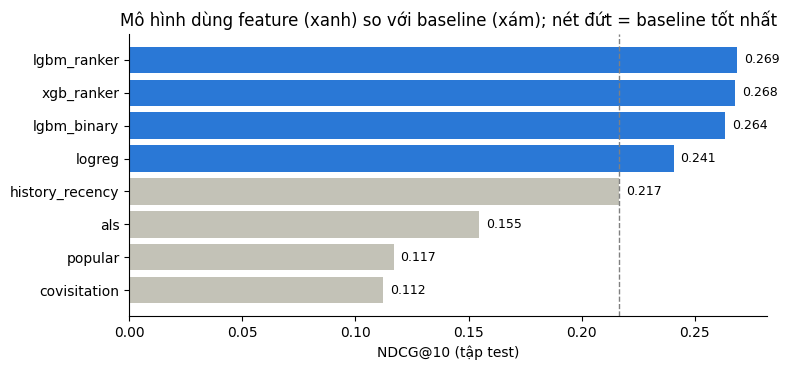

In [38]:
rows, pu = [], {}                     # pu: NDCG@10 từng user trên test, dùng cho so sánh cặp
for split in ("val", "test"):
    s = S[split]
    store = pu if split == "test" else None
    for name, fn in BASELINES.items():
        rows.append({"model": name, "type": "baseline", "split": split,
                     **score_and_eval(s["X"], fn(s["X"]), s["truth"], cfg, s["n_catalog"], store, name)})
    for name in MODELS:
        rows.append({"model": name, "type": "feature_model", "split": split,
                     **score_and_eval(s["X"], preds[name](s["X"]), s["truth"], cfg, s["n_catalog"], store, name)})
comp = pd.DataFrame(rows)
cols = ["model", "type", "ndcg@10", "recall@10", "hitrate@10", "map@10", "coverage@10",
        "ndcg@10_budget", "over_budget@20_no_filter"]
te = comp[comp["split"] == "test"].sort_values("ndcg@10", ascending=False)[cols].reset_index(drop=True)
display(te)

fig, ax = plt.subplots(figsize=(8, 3.8))
colors = ["#2a78d6" if t_ == "feature_model" else "#c3c2b7" for t_ in te["type"]]
ax.barh(te["model"][::-1], te["ndcg@10"][::-1], color=colors[::-1])
ax.axvline(te.loc[te["type"] == "baseline", "ndcg@10"].max(), ls="--", color="gray", lw=1)
for y, v in enumerate(te["ndcg@10"][::-1]):
    ax.text(v + 0.003, y, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("NDCG@10 (tập test)")
ax.set_title("Mô hình dùng feature (xanh) so với baseline (xám); nét đứt = baseline tốt nhất")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 6.1. Chọn mô hình và so sánh cặp

Mô hình được **chọn trên tập val** (không nhìn test). Sau đó so từng mô hình với mô hình bàn giao trên **cùng từng user test**.

**Vì sao cần so cặp:** chạy lại cùng code có thể lệch khoảng 0.004 NDCG, nên chênh lệch hai con số trung bình không nói lên được gì. Khoảng tin cậy **không chứa 0** → chênh lệch có thật (`real`); **chứa 0** → chưa phân biệt được (`noise`).

In [39]:
v = comp[(comp["split"] == "val") & (comp["type"] == "feature_model")]
val_best = v.sort_values(cfg.select_metric, ascending=False).iloc[0]["model"]
BEST = cfg.final_model or val_best
print(f"Tốt nhất trên val: {val_best}. Mô hình bàn giao: {BEST}")

pairs = []
for name in te["model"]:
    d_, lo, hi, _ = paired_bootstrap(pu[BEST], pu[name], cfg.n_boot, cfg.seed)
    pairs.append({"model": name, "ndcg@10": pu[name].mean(), "diff_vs_best": d_, "ci_low": lo, "ci_high": hi,
                  "verdict": "-" if name == BEST else ("real" if (lo > 0 or hi < 0) else "noise"),
                  "train_seconds": times.get(name, np.nan)})
pairs = pd.DataFrame(pairs).set_index("model")
display(pairs)

Tốt nhất trên val: xgb_ranker. Mô hình bàn giao: lgbm_ranker


,ndcg@10,diff_vs_best,ci_low,ci_high,verdict,train_seconds
model,,,,,,
lgbm_ranker,0.2686,0.0000,0.0000,0.0000,-,3.2669
xgb_ranker,0.2680,-0.0006,-0.0037,0.0021,noise,15.4159
lgbm_binary,0.2635,-0.0051,-0.0085,-0.0016,real,3.0692
logreg,0.2407,-0.0280,-0.0332,-0.0226,real,4.2839
history_recency,0.2166,-0.0520,-0.0576,-0.0457,real,NaN
als,0.1548,-0.1138,-0.1230,-0.1047,real,NaN
popular,0.1168,-0.1518,-0.1618,-0.1414,real,NaN
covisitation,0.1124,-0.1562,-0.1668,-0.1453,real,NaN


**Kết luận (ổn định qua các lần chạy):**

- LightGBM ranker và XGBoost ranker **ngang nhau** (khoảng tin cậy chứa 0). Chọn LightGBM vì train nhanh hơn nhiều.
- LightGBM binary kém hơn một chút nhưng có thật; logistic regression kém rõ. Học **thứ tự** tốt hơn học phân loại từng cặp.
- Mọi baseline đều kém hơn rõ ràng. Riêng "gợi ý lại món vừa xem" đã đạt khoảng 0.217: phần lớn giá trị của mô hình nằm ở chỗ **sắp xếp lại các món user đang cân nhắc cho đúng**.
- **Ngân sách:** nếu không lọc, khoảng 25% món trong top 20 vượt ngân sách, nên bước lọc là cần thiết. Lọc xong NDCG giảm khoảng 7%, vì có user mua món đắt hơn ngân sách mô phỏng.
- **Coverage thấp** (vài %): mô hình tập trung vào số ít món; cần lưu ý nếu muốn tăng tính khám phá.

## 7. Ablation: feature nào thật sự có ích

Train lại LightGBM ranker nhiều lần, mỗi lần **bớt** hoặc **thêm dần** một phần feature, rồi so cặp với mô hình đủ feature:

- `cumulative`: thêm dần từng nhóm, cho thấy mỗi nhóm thêm được bao nhiêu.
- `drop_one_group`: bỏ một nhóm, cho thấy nhóm đó có thay thế được không.
- `drop_one_feature`: bỏ từng feature còn dùng của nhóm thử nghiệm dynamics.

Mỗi cấu hình train 3 seed rồi lấy trung bình NDCG từng user, để giảm nhiễu do ngẫu nhiên khi train. `diff_vs_full` âm và `real` nghĩa là bỏ đi thì kết quả kém đi thật, tức là phần đó có ích.

In [40]:
abl_path = os.path.join(ARTIFACTS, "results", "ablation.csv")
if RUN_ABLATION or not os.path.exists(abl_path):
    def fit_avg(fs):
        runs = []
        for i in range(cfg.n_seeds):
            _, pred = fit_lgbm_ranker(tr, va, fs, replace(cfg, seed=cfg.seed + i))
            Sx = S["test"]["X"][["user_id", "product_id"]].copy()
            Sx["score"] = np.asarray(pred(S["test"]["X"]), dtype="float64")
            runs.append(per_user_ndcg(Sx, "score", S["test"]["truth"], 10))
        return pd.concat(runs, axis=1).mean(axis=1)

    fn = lambda gs: [f for f in feature_names(gs) if f in FEATS]
    groups = [g for g in GROUPS if fn([g])]
    base = fit_avg(FEATS)
    pu["abl:full"] = base
    exps = [("cumulative", " + ".join(groups[:i]), fn(groups[:i])) for i in range(1, len(groups) + 1)]
    exps += [("drop_one_group", f"without {g}", fn([x for x in groups if x != g])) for g in groups]
    exps += [("drop_one_feature", f"without {f}", [x for x in FEATS if x != f]) for f in fn(["dynamics"])]
    abl = []
    for kind, label, fs in exps:
        r = fit_avg(fs)
        pu[f"abl:{label}"] = r
        d_, lo, hi, _ = paired_bootstrap(base, r, cfg.n_boot, cfg.seed)
        abl.append({"experiment": kind, "groups": label, "ndcg@10": r.mean(), "diff_vs_full": d_,
                    "ci_low": lo, "ci_high": hi, "verdict": "real" if (lo > 0 or hi < 0) else "noise"})
    abl = pd.DataFrame(abl)
    tick(f"ablation: {len(abl)} thí nghiệm x {cfg.n_seeds} seed, mô hình đủ feature NDCG@10 = {base.mean():.4f}")
else:
    abl = pd.read_csv(abl_path)
    print(f"Đọc kết quả đã lưu: {abl_path}")
with pd.option_context("display.max_colwidth", 90):
    display(abl)

[   921s] ablation: 16 thí nghiệm x 3 seed, mô hình đủ feature NDCG@10 = 0.2670


,experiment,groups,ndcg@10,diff_vs_full,ci_low,ci_high,verdict
0,cumulative,candidate,0.2357,-0.0313,-0.0361,-0.0262,real
1,cumulative,candidate + item,0.2363,-0.0307,-0.0354,-0.0258,real
2,cumulative,candidate + item + user,0.2388,-0.0282,-0.0327,-0.0238,real
3,cumulative,candidate + item + user + user_item,0.2658,-0.0012,-0.0036,0.0013,noise
4,cumulative,candidate + item + user + user_item + affinity,0.2664,-0.0006,-0.0028,0.0015,noise
5,cumulative,candidate + item + user + user_item + affinity + price_budget,0.2662,-0.0009,-0.0028,0.0011,noise
6,cumulative,candidate + item + user + user_item + affinity + price_budget + dynamics,0.2670,0.0000,0.0000,0.0000,noise
7,drop_one_group,without candidate,0.2645,-0.0025,-0.0054,0.0003,noise
8,drop_one_group,without item,0.2659,-0.0012,-0.0034,0.0012,noise
9,drop_one_group,without user,0.2658,-0.0012,-0.0032,0.0006,noise


**Các lần thử nghiệm feature:**

| Lần | Thay đổi | Số feature | NDCG@10 (lgbm_ranker) | Kết luận |
|---|---|---|---|---|
| v1 | Bản gốc, 6 nhóm | 45 | 0.266 | Mốc so sánh |
| v2 | Thêm `ui_views_last_session` | 46 | 0.267 | Không phân biệt được với nhiễu |
| v3 | Thêm 7 feature nhóm dynamics; bắt đầu so cặp và chạy 3 seed | 52 | 0.267 | 2/7 feature mới có vẻ có ích |
| final | 45 + `price_vs_user_cat` + `ui_days_since_cart` | 47 | 0.269 | Tương đương bộ 45 (chênh khoảng 0.001, nhiễu); bản bàn giao |

**Bài học về feature:**

1. **Nhóm user_item quyết định.** Hành vi của user với chính món đó là nhóm duy nhất bỏ đi thì kết quả giảm thật ở **mọi** lần chạy. Các nhóm khác đóng góp nhỏ (0.001–0.004), lúc ra `real` lúc ra `noise`.
2. **Feature chỉ giúp khi mang thông tin mới.** Đo lại độ gần đây theo cách khác (theo phiên thay vì theo ngày) không thêm gì, vì `hist_rank` và `ui_days_since_last` đã chứa thông tin đó.
3. **Kết quả nhỏ phải lặp lại được mới tin.** Bảng ablation ở v3 có 21 phép so sánh, nên khoảng 1 kết quả `real` có thể chỉ do may rủi. `price_vs_user_cat` là ví dụ: có ích ở v3, nhiễu ở final. `ui_days_since_cart` ra cùng một mức (khoảng −0.0017, sát ngưỡng) ở cả hai lần.
4. **Hai feature mới vẫn được giữ** vì không làm kết quả kém đi, tính nhanh, dễ giải thích, và `price_vs_user_cat` gắn trực tiếp với gợi ý theo ngân sách.

## 8. Feature importance

**Gain** = tổng mức cải thiện mà mỗi feature mang lại khi được dùng để chia nhánh trong cây của LightGBM ranker.

**Gain khác ablation:** gain cho biết mô hình **dùng** feature nào nhiều; ablation cho biết feature nào **không thể thiếu**. Hai feature cùng chứa một thông tin thì chia gain cho nhau, nhưng bỏ một cái đi thì cái kia gánh thay. Ví dụ ở v3: `ui_view_share_30d` chiếm 29% gain, nhưng bỏ đi chỉ mất 0.0004.

,feature,group,gain_share,why
0,hist_rank,candidate,0.2625,Người mua rất hay quay lại món vừa xem; món càng gần đây càng dễ được mua
1,ui_views,user_item,0.0842,Xem đi xem lại là tín hiệu mua rất mạnh
2,ui_days_since_last,user_item,0.0434,Tương tác càng gần mốc dự đoán càng có giá trị
3,item_purchases_30d,item,0.0428,Bằng chứng trực tiếp món bán được
4,n_sources,candidate,0.0399,Món được nhiều tín hiệu độc lập cùng chỉ ra thường liên quan hơn
5,ui_days_since_cart,dynamics,0.0380,Giỏ hàng vừa thêm hôm qua khác hẳn giỏ hàng bỏ quên 3 tuần
6,aff_brand,affinity,0.0303,Trung thành thương hiệu
7,item_carts_30d,item,0.0298,Ý định mua mạnh hơn lượt xem
8,covisit_score,candidate,0.0297,Bắt quan hệ thay thế/bổ sung giữa sản phẩm (xem điện thoại thì hay xem ốp lưng)
9,price_vs_user_cat,dynamics,0.0294,Món rẻ hơn những gì user đang cân nhắc trong cùng loại: tín hiệu cho gợi ý theo ngân sách


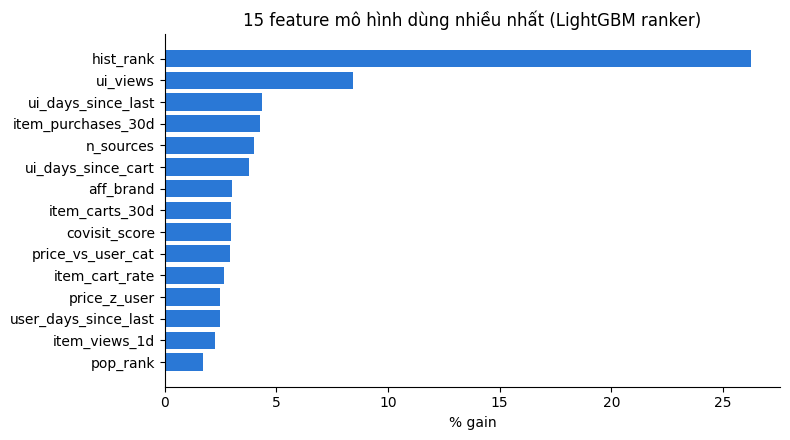

,% gain theo nhóm
group,
candidate,0.3737
item,0.2183
user_item,0.1489
user,0.0930
dynamics,0.0674
price_budget,0.0510
affinity,0.0476


In [41]:
lg = fitted["lgbm_ranker"]
imp = pd.DataFrame({"feature": FEATS, "gain": lg.booster_.feature_importance("gain")})
imp["gain_share"] = imp["gain"] / imp["gain"].sum()
imp["group"] = imp["feature"].map(lambda f: FEATURES[f]["group"])
imp["why"] = imp["feature"].map(lambda f: FEATURES[f]["why"])
imp = imp.sort_values("gain_share", ascending=False).reset_index(drop=True)
with pd.option_context("display.max_colwidth", 100):
    display(imp.head(15)[["feature", "group", "gain_share", "why"]])

top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top["feature"], top["gain_share"] * 100, color="#2a78d6")
ax.set_xlabel("% gain")
ax.set_title("15 feature mô hình dùng nhiều nhất (LightGBM ranker)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
display(imp.groupby("group")["gain_share"].sum().sort_values(ascending=False).rename("% gain theo nhóm").to_frame())

## 9. Lưu mô hình và kết quả

Lưu vào `ARTIFACTS/`:

| File | Nội dung |
|---|---|
| `models/best_model.joblib` | Mô hình bàn giao |
| `models/best_model_meta.json` | Danh sách feature, chỉ số val/test, khoảng dữ liệu, mốc thời gian, cấu hình. Inference đọc file này để biết dùng feature nào |
| `results/model_comparison.csv` | Chỉ số mọi mô hình và baseline trên val và test |
| `results/paired_vs_best.csv` | So cặp với mô hình bàn giao |
| `results/ablation.csv` | Kết quả ablation |
| `results/feature_importance.csv` | Gain từng feature, kèm lý do |
| `results/feature_catalog.md` | Danh mục feature |
| `results/per_user_ndcg10_test.parquet` | NDCG@10 từng user test, để so với lần chạy khác |

In [42]:
os.makedirs(os.path.join(ARTIFACTS, "models"), exist_ok=True)
os.makedirs(os.path.join(ARTIFACTS, "results"), exist_ok=True)

joblib.dump(fitted[BEST], os.path.join(ARTIFACTS, "models", "best_model.joblib"))
row = lambda split: comp[(comp.model == BEST) & (comp.split == split)].iloc[0].drop(["model", "type", "split"]).to_dict()
meta = {"model": BEST, "val_best_model": val_best, "features": FEATS, "select_metric": cfg.select_metric,
        "val": row("val"), "test": row("test"),
        "data_range": [str(df["event_time"].min()), str(df["event_time"].max())],
        "cutoffs": {k: str(v) for k, v in cuts.items()}, "config": cfg.__dict__}
with open(os.path.join(ARTIFACTS, "models", "best_model_meta.json"), "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2, default=str)

res = os.path.join(ARTIFACTS, "results")
comp.to_csv(os.path.join(res, "model_comparison.csv"), index=False, encoding="utf-8-sig")
pairs.reset_index().to_csv(os.path.join(res, "paired_vs_best.csv"), index=False, encoding="utf-8-sig")
abl.to_csv(os.path.join(res, "ablation.csv"), index=False, encoding="utf-8-sig")
imp.to_csv(os.path.join(res, "feature_importance.csv"), index=False, encoding="utf-8-sig")
pd.DataFrame(pu).rename_axis("user_id").reset_index().to_parquet(os.path.join(res, "per_user_ndcg10_test.parquet"), index=False)
with open(os.path.join(res, "feature_catalog.md"), "w", encoding="utf-8") as f:
    f.write(describe_markdown())
print("Đã lưu:", *sorted(glob.glob(os.path.join(ARTIFACTS, "*", "*"))), sep="\n  ")

Đã lưu:
  artifacts\models\best_model.joblib
  artifacts\models\best_model_meta.json
  artifacts\results\ablation.csv
  artifacts\results\feature_catalog.md
  artifacts\results\feature_importance.csv
  artifacts\results\model_comparison.csv
  artifacts\results\paired_vs_best.csv
  artifacts\results\per_user_ndcg10_test.parquet


## 10. Inference: dùng mô hình để gợi ý

Lớp `Recommender` nạp mô hình và metadata đã lưu, rồi gợi ý top N cho một danh sách user. Nó dùng **chung** hàm sinh ứng viên (`generate`) và tính feature (`build_features`) với lúc train, nên không lệch giữa huấn luyện và phục vụ.

Luồng khi hệ thống chạy thật (khớp khối *Product recommendations* trong kiến trúc):

1. Request: `user_id`, `max_price` (ngân sách mỗi sản phẩm), số món cần.
2. User tắt cá nhân hóa, user mới, hoặc mô hình lỗi/quá thời gian → trả danh sách **phổ biến**.
3. Ngược lại: sinh ứng viên → tính feature → mô hình chấm điểm → **chỉ giữ món trong ngân sách** → top N.
4. Ghi log lượt gợi ý để đo hiệu quả sau này.

In [43]:
class Recommender:
    def __init__(self, artifacts_dir="artifacts"):
        md = os.path.join(artifacts_dir, "models")
        self.model = joblib.load(os.path.join(md, "best_model.joblib"))
        with open(os.path.join(md, "best_model_meta.json"), encoding="utf-8") as f:
            self.meta = json.load(f)
        self.features = self.meta["features"]
        c = self.meta["config"]
        self.cfg = Config(**{k: v for k, v in c.items() if k in Config.__dataclass_fields__})

    def _score(self, X):
        if hasattr(self.model, "predict_proba"):
            return self.model.predict_proba(X[self.features])[:, 1]
        return self.model.predict(X[self.features])

    def recommend(self, events, user_ids, t=None, budget=None, n=10):
        """events: DataFrame sự kiện (đã qua data.load_events). budget: số (VND) hoặc dict user_id -> ngân sách.
        Trả về: user_id, rank, product_id, score, price, source (model)."""
        t = t or events["event_time"].max() + pd.Timedelta(seconds=1)
        hist = events[events["event_time"] < t]
        users = np.asarray(user_ids)
        cand = generate(hist, users, t, self.cfg)
        b = None
        if budget is not None:
            b = pd.Series(budget if isinstance(budget, dict) else {u: budget for u in users}, dtype="float64")
        X = build_features(hist, t, cand, budget=b)
        X["score"] = self._score(X)
        if b is not None:                       # Eligible: chỉ giữ món trong ngân sách
            X = X[X["in_budget"] == 1]
        X = X.sort_values(["user_id", "score"], ascending=[True, False])
        X["rank"] = X.groupby("user_id").cumcount() + 1
        out = X[X["rank"] <= n][["user_id", "rank", "product_id", "score", "item_price"]]
        return out.rename(columns={"item_price": "price"}).reset_index(drop=True)

In [44]:
rec = Recommender(ARTIFACTS)
print(f"Mô hình: {rec.meta['model']}, {len(rec.features)} feature")
demo_users = df["user_id"].value_counts().index[:3]
print("\nKhông giới hạn ngân sách:")
display(rec.recommend(df, demo_users, n=5))
print("Ngân sách 100 / sản phẩm:")
display(rec.recommend(df, demo_users, budget=100.0, n=5))

Mô hình: lgbm_ranker, 47 feature

Không giới hạn ngân sách:


,user_id,rank,product_id,score,price
0,537169676,1,26300352,1.9069,221.1100
1,537169676,2,26300088,1.7112,188.1600
2,537169676,3,26300075,1.6327,209.7900
3,537169676,4,26300087,1.6281,257.1500
4,537169676,5,26300076,1.5931,224.4600
5,568790544,1,4803879,1.1131,58.0900
6,568790544,2,1801882,0.8888,419.0300
7,568790544,3,1802022,0.7485,481.6100
8,568790544,4,1307310,0.6063,277.7400
9,568790544,5,1004836,0.4772,231.1500


Ngân sách 100 / sản phẩm:


,user_id,rank,product_id,score,price
0,537169676,1,16500007,0.7134,62.5100
1,537169676,2,26401414,-1.0650,60.7500
2,537169676,3,12703015,-1.2575,40.9300
3,537169676,4,5100816,-1.3165,26.7200
4,537169676,5,100079046,-1.4707,47.8800
5,568790544,1,4803879,1.0383,58.0900
6,568790544,2,5100376,0.1409,64.0000
7,568790544,3,4804295,0.0620,22.6600
8,568790544,4,4804660,-0.8398,20.8500
9,568790544,5,1004209,-1.0297,81.9800


**Lưu ý:** cột `score` là điểm xếp hạng, không phải xác suất (âm cũng được); chỉ thứ tự trong cùng một user là có nghĩa. Khi ngân sách thấp hơn hẳn mức giá user hay xem, danh sách sau lọc thường gồm món điểm thấp và khác loại, vì tầng ứng viên chưa có nguồn "món cùng loại, rẻ hơn" (mục 3.2).

### 10.1. Kiểm tra trên trường hợp cụ thể

Quay về mốc test, gợi ý cho 5 user có mua hàng sau mốc, rồi đánh dấu từng món gợi ý: user **đã xem trước đó chưa** (`da_xem`), và **có thật sự mua sau đó không** (`da_mua`).

In [45]:
t = S["test"]["t"]
after = df[(df["event_time"] >= t) & (df["event_time"] < t + L) & (df["event_type"] == "purchase")]
before = df[df["event_time"] < t]
buyers = after.loc[after["user_id"].isin(before["user_id"]), "user_id"].value_counts().index[:5]
r = rec.recommend(df, buyers, t=t, n=10)
seen_b = before[["user_id", "product_id"]].drop_duplicates().assign(da_xem=1)
bought = after[["user_id", "product_id"]].drop_duplicates().assign(da_mua=1)
r = r.merge(seen_b, how="left").merge(bought, how="left").fillna({"da_xem": 0, "da_mua": 0})
display(r)
print(f"Tỷ lệ món gợi ý user đã xem trước đó: {r['da_xem'].mean():.0%}")
print(f"Số user có ít nhất 1 món gợi ý được mua thật: {int(r.groupby('user_id')['da_mua'].max().sum())} / {len(buyers)}")

,user_id,rank,product_id,score,price,da_xem,da_mua
0,543449828,1,3601405,1.3799,195.6000,1.0000,1.0000
1,543449828,2,100019294,1.0350,587.1500,1.0000,1.0000
2,543449828,3,7201137,0.5252,21.7500,1.0000,0.0000
3,543449828,4,100070324,-0.0883,33.4400,1.0000,0.0000
4,543449828,5,7203227,-0.5036,25.2300,1.0000,0.0000
5,543449828,6,3600661,-0.5123,303.7100,0.0000,0.0000
6,543449828,7,3601494,-0.5313,249.6600,0.0000,0.0000
7,543449828,8,15100297,-0.6524,275.1700,1.0000,0.0000
8,543449828,9,1004767,-0.6566,226.1800,0.0000,0.0000
9,543449828,10,3601438,-0.6796,216.2000,0.0000,0.0000


Tỷ lệ món gợi ý user đã xem trước đó: 76%
Số user có ít nhất 1 món gợi ý được mua thật: 5 / 5


## 11. Kết luận, hạn chế và yêu cầu dữ liệu cho database

### Kết luận

- **Mô hình bàn giao:** LightGBM ranker, 47 feature, NDCG@10 khoảng 0.269, hơn baseline tốt nhất khoảng 24% (chênh lệch có thật). 44% user có ít nhất 1 món họ mua nằm trong top 10.
- **Feature quan trọng hơn chọn mô hình:** feature đóng góp khoảng +0.03 NDCG; đổi giữa các mô hình cây gần như không tạo khác biệt.
- **Nhóm user_item quyết định.** Các nhóm khác đóng góp nhỏ.
- **Phương pháp:** chia theo thời gian, kiểm tra chống rò rỉ, chọn mô hình trên val, so cặp có khoảng tin cậy, ablation nhiều seed.

### Hạn chế

- **Trần candidate recall khoảng 0.61:** 39% món được mua không có trong danh sách ứng viên (mục 3.2). Đây là hướng còn nhiều dư địa nhất.
- **Gợi ý yếu khi ngân sách thấp hơn hẳn thói quen của user,** vì chưa có nguồn ứng viên theo danh mục và ngân sách.
- **Ngân sách đang mô phỏng;** chưa đánh giá user mới; mới chạy mẫu 5% user; coverage thấp.

### Hướng tiếp theo

1. Thêm nguồn ứng viên "món cùng `category_id` với món user đang xem, giá trong ngân sách". Mục 3.2 cho biết mức tăng trần tối đa.
2. Chạy mẫu lớn hơn (10–20% user) trên Kaggle để thu hẹp khoảng tin cậy.
3. Thống nhất metric chính (NDCG@10 hay Recall@10) và độ dài cửa sổ nhãn với phần Metrics.
4. Khi đã ổn định: tách các phần code của notebook ra module (`data`, `candidates`, `features`, `evaluate`, `train`, `recommend`) để ghép vào backend.

### Yêu cầu dữ liệu cho database

Để khi hệ thống chạy thật tính lại được đúng các feature và nguồn ứng viên trên, đối chiếu với thiết kế DB v1.1:

| Mô hình cần | Lấy từ | Trạng thái |
|---|---|---|
| Lịch sử xem, thêm giỏ, mua theo user và phiên | `behavior_events` (`user_id`, `session_id`, `product_id`, `event_type`, `occurred_at`) | Có |
| **Giá tại thời điểm xem / thêm giỏ** (feature giá của user, ngân sách) | `behavior_events.unit_price` | **Cần bắt buộc cho `product_view` và `add_to_cart`**, hiện chỉ bắt buộc khi `purchase` |
| Lượt xem, giỏ, mua của món theo 1/7/30 ngày | `product_daily_stats` | Có |
| Thứ hạng phổ biến, fallback Popular | `product_popularity` | Có |
| Co-visitation (nguồn "cùng phiên") | `product_similarities` | Nên thêm cột `method` để phân biệt cách tính |
| Ứng viên ALS tính sẵn | `user_recommendations` | Nên thêm cột `source` |
| Danh mục, danh mục cha, thương hiệu, giá hiện tại, ngày đăng | `products`, `categories`, `brands` | Có |
| Ngân sách của request, log gợi ý | `recommendation_requests`, `recommendation_items` | Có |
| Tắt cá nhân hóa | `privacy_settings` | Có |
| Phiên bản mô hình, danh sách feature, chỉ số | (chưa có) | Nên thêm bảng `ml_models`, nội dung như `best_model_meta.json` |

**Lưu ý đơn vị giá:** đa số feature giá là tỷ lệ nên dùng được với VND, nhưng `item_price`, `user_price_mean`, `user_price_std` là giá tuyệt đối. Khi có dữ liệu thật của hệ thống cần train lại mô hình.

In [46]:
tick("xong toàn bộ notebook")

[  1281s] xong toàn bộ notebook
